### Статистический анализ скидочной политики и прибыльности розничной сети «Соседушка»

**Бизнес-задача:** исследовать взаимосвязь скидок, размера покупательской корзины и валовой прибыли розничной сети.

**Цель:** выявить статистически обоснованные различия и закономерности, которые могут быть использованы для оценки скидочной политики.

**Данные:** синтетический датасет розничных продаж за 2024–2025 годы.

**Методы:** описательная статистика, визуализация распределений, доверительные интервалы, статистические критерии и оценка размеров эффекта.

### Краткое резюме исследования

**Цель исследования:** оценить взаимосвязь скидок, размера покупательской корзины и валовой прибыли розничной сети «Соседушка» и определить направления совершенствования скидочной политики.

**Данные:** 22 790 чеков, 81 238 товарных позиций, 20 магазинов трёх форматов за 2024–2025 годы. Выполнен разведочный статистический анализ и проверены шесть гипотез.

#### Ключевые результаты

**1. Более высокий средний чек скидочных покупок не свидетельствует об эффективности скидок.**

Первоначальное сравнение показало, что средний чек покупок со скидкой выше на 24–93% в зависимости от формата магазина. Однако после учёта количества товарных позиций скорректированная разница изменила направление и составила от −28,70 до −97,27 ₽.

Различия связаны в том числе с тем, что вероятность наличия скидочной позиции увеличивается вместе с размером корзины.

**2. Скидочные покупки характеризуются более низкой скорректированной валовой прибылью на чек.**

После учёта формата магазина и количества товарных позиций выявлена отрицательная статистическая связь наличия скидки с оценочной валовой прибылью: от −30,65 до −58,87 ₽ в зависимости от формата.

Результаты не позволяют установить причинное влияние скидок на финансовый результат.

**3. Формат магазина существенно влияет на интерпретацию финансовых показателей.**

Средняя валовая прибыль на чек составляет 127,88 ₽ в магазинах у дома, 253,88 ₽ в супермаркетах и 438,80 ₽ в гипермаркетах. Статистический анализ выявил выраженные различия распределений валовой прибыли между форматами.

#### Рекомендации

- Пересмотреть систему оценки скидочной политики: использовать валовую прибыль, маржу, размер корзины и эффективный процент скидки совместно со средним чеком.
- Провести приоритетный анализ экономики скидочных покупок в магазинах у дома, где наблюдается наиболее выраженное снижение относительной маржинальности.
- Установить отдельные аналитические ориентиры финансовых показателей для каждого формата магазинов.
- Перед изменением скидочных условий проверить их причинный эффект с помощью контролируемого эксперимента.

#### Ограничения

Исследование выполнено на синтетических данных. Валовая прибыль рассчитана по справочным закупочным ценам без исторической детализации. Выявленные статистические связи не доказывают причинного влияния скидок на поведение покупателей и прибыль сети.

**Основной вывод:** средний чек не должен использоваться как самостоятельный показатель эффективности скидочной программы. Управленческие решения необходимо основывать на финансовом результате сопоставимых покупок и проверке причинного эффекта скидок.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
from scipy import stats
from statsmodels.stats.multitest import multipletests
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
import seaborn as sns
from itertools import combinations

### Этап 1. Аудит исходных данных
**Цель:** понять структуру, гранулярность и качество исходных таблиц до статистических расчётов.

#### 1.1. Загружаем Excel и изучаем структуру

In [2]:
DATA_PATH = Path("../data/raw/simulative_retail_sales.xlsx")

assert DATA_PATH.exists(), f"Файл не найден: {DATA_PATH.resolve()}"

excel = pd.ExcelFile(DATA_PATH)

print("Листы Excel:")
for sheet in excel.sheet_names:
    print(f"- {sheet}")

Листы Excel:
- README
- fact_sales
- dim_products
- dim_stores
- dim_customers
- dim_suppliers


#### 1.2. Загрузка и первичный анализ структуры данных
На этом этапе проверяем состав исходных таблиц, количество наблюдений, названия столбцов и типы данных.

**Цель проверки** — определить структуру датасета, выявить потенциальные проблемы с типами данных и подготовить основу для дальнейшего анализа качества.

In [3]:
# Загружаем таблицы в словарь DataFrame
sheet_names = [
    'fact_sales',
    'dim_products',
    'dim_stores',
    'dim_customers',
    'dim_suppliers'
]

tables = {
    sheet: pd.read_excel(DATA_PATH, sheet_name=sheet)
    for sheet in sheet_names
}

# Формируем сводную информацию
structure_summary = pd.DataFrame([
    {
        "Таблица": name,
        "Строк": df.shape[0],
        "Столбцов": df.shape[1]
    }
    for name, df in tables.items()
])

display(structure_summary)

,Таблица,Строк,Столбцов
0,fact_sales,81238,10
1,dim_products,101,8
2,dim_stores,20,7
3,dim_customers,5000,7
4,dim_suppliers,20,4


#### 1.3. Проверяем названия столбцов и типы данных

In [4]:
for name, df in tables.items():
    print(f"\n{'=' * 60}")
    print(f"Таблица: {name}")
    print(f"{'=' * 60}")

    df.info()
    print("\nНазвания столбцов:")
    print(df.columns.tolist())


Таблица: fact_sales
<class 'pandas.DataFrame'>
RangeIndex: 81238 entries, 0 to 81237
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   id_чека          81238 non-null  int64         
 1   дата_время       81238 non-null  datetime64[us]
 2   id_магазина      81238 non-null  int64         
 3   id_товара        81238 non-null  int64         
 4   id_клиента       44744 non-null  float64       
 5   количество       81238 non-null  int64         
 6   цена_за_единицу  81238 non-null  float64       
 7   скидка_процент   81238 non-null  int64         
 8   сумма_строки     81238 non-null  float64       
 9   способ_оплаты    81238 non-null  str           
dtypes: datetime64[us](1), float64(3), int64(5), str(1)
memory usage: 6.2 MB

Названия столбцов:
['id_чека', 'дата_время', 'id_магазина', 'id_товара', 'id_клиента', 'количество', 'цена_за_единицу', 'скидка_процент', 'сумма_строки', 'способ_оплат

#### 1.4. Проверка гранулярности и уникальности ключей
Перед статистическим анализом необходимо определить единицу наблюдения и проверить уникальность идентификаторов в справочниках.

Дублирование ключей может привести к размножению строк при объединении таблиц и, как следствие, к искажению финансовых показателей.

In [5]:
# Проверяем уникальность ключей справочников
dimension_keys = {
    'dim_products': 'id_товара',
    'dim_stores': 'id_магазина',
    'dim_customers': 'id_клиента',
    'dim_suppliers': 'id_поставщика'
}

key_checks = []

for table_name, key in dimension_keys.items():
    df = tables[table_name]

    key_checks.append({
        "Таблица": table_name,
        "Ключ": key,
        "Строк": len(df),
        "Уникальных ключей": df[key].nunique(),
        "Дубликатов": df[key].duplicated().sum(),
        "Пропусков": df[key].isna().sum()
    })

    display(pd.DataFrame(key_checks))

,Таблица,Ключ,Строк,Уникальных ключей,Дубликатов,Пропусков
0,dim_products,id_товара,101,101,0,0


,Таблица,Ключ,Строк,Уникальных ключей,Дубликатов,Пропусков
0,dim_products,id_товара,101,101,0,0
1,dim_stores,id_магазина,20,20,0,0


,Таблица,Ключ,Строк,Уникальных ключей,Дубликатов,Пропусков
0,dim_products,id_товара,101,101,0,0
1,dim_stores,id_магазина,20,20,0,0
2,dim_customers,id_клиента,5000,5000,0,0


,Таблица,Ключ,Строк,Уникальных ключей,Дубликатов,Пропусков
0,dim_products,id_товара,101,101,0,0
1,dim_stores,id_магазина,20,20,0,0
2,dim_customers,id_клиента,5000,5000,0,0
3,dim_suppliers,id_поставщика,20,20,0,0


In [6]:
# Проверяем структуру чеков
sales = tables["fact_sales"]

check_summary = pd.DataFrame({
    "Показатель": [
        "Количество строк",
        "Количество уникальных чеков",
        "Среднее количество строк в чеке",
        "Максимальное количество строк в чеке",
        "Полностью дублирующиеся строки"
    ],
    "Значение": [
        len(sales),
        sales["id_чека"].nunique(),
        len(sales) / sales["id_чека"].nunique(),
        sales.groupby("id_чека").size().max(),
        sales.duplicated().sum()
    ]
})

display(check_summary)

,Показатель,Значение
0,Количество строк,81238.000000
1,Количество уникальных чеков,22790.000000
2,Среднее количество строк в чеке,3.564634
3,Максимальное количество строк в чеке,12.000000
4,Полностью дублирующиеся строки,0.000000


In [7]:
# Проверяем согласованность данных внутри чека
check_consistency = (
    sales.groupby("id_чека")
    .agg(
        stores=("id_магазина", "nunique"),
        timestamps=("дата_время", "nunique"),
        customers=("id_клиента", lambda x: x.nunique(dropna=False)),
        payments=("способ_оплаты", "nunique")
    )
)

consistency_result = pd.DataFrame({
    "Проверка": [
        "Чек связан с несколькими магазинами",
        "Чек содержит разные даты/время",
        "Чек связан с разными покупателями",
        "Чек содержит разные способы оплаты"
    ],
    "Количество проблемных чеков": [
        (check_consistency["stores"] > 1).sum(),
        (check_consistency["timestamps"] > 1).sum(),
        (check_consistency["customers"] > 1).sum(),
        (check_consistency["payments"] > 1).sum()
    ]
})

display(consistency_result)

,Проверка,Количество проблемных чеков
0,Чек связан с несколькими магазинами,0
1,Чек содержит разные даты/время,0
2,Чек связан с разными покупателями,0
3,Чек содержит разные способы оплаты,0


#### Вывод по проверке ключей и гранулярности

Проверена уникальность идентификаторов четырёх справочников. Дублирующиеся и отсутствующие значения первичных ключей не обнаружены.

Таблица продаж содержит 81 238 строк, объединённых в 22 790 уникальных чеков. Среднее количество товарных позиций на чек составляет 3,56, максимальное — 12.

Полных дубликатов строк не обнаружено. Все чеки согласованы по магазину, дате и времени, покупателю и способу оплаты.

**Единица наблюдения:** исходная строка соответствует товарной позиции продажи; для анализа среднего чека, размера корзины и валовой прибыли на покупку потребуется агрегация до уровня чека.

Следующий этап контроля качества — проверка соответствия внешних ключей справочникам, пропусков и допустимых диапазонов значений.

#### 1.5. Проверка ссылочной целостности

In [8]:
foreign_keys = [
    ("fact_sales", "id_товара", "dim_products", "id_товара"),
    ("fact_sales", "id_магазина", "dim_stores", "id_магазина"),
    ("fact_sales", "id_клиента", "dim_customers", "id_клиента"),
    ("dim_products", "id_поставщика", "dim_suppliers", "id_поставщика")
]

fk_results = []

for fact_name, fact_key, dim_name, dim_key in foreign_keys:
    fact = tables[fact_name]
    dim = tables[dim_name]

    # Для клиентов отсутствие ID допускается
    values = fact[fact_key].dropna()

    missing_mask = ~values.isin(dim[dim_key])

    fk_results.append({
        "Таблица": fact_name,
        "Внешний ключ": fact_key,
        "Справочник": dim_name,
        "Несопоставленных строк": missing_mask.sum(),
        "Уникальных отсутствующих ID": values[missing_mask].nunique()
    })

display(pd.DataFrame(fk_results))

,Таблица,Внешний ключ,Справочник,Несопоставленных строк,Уникальных отсутствующих ID
0,fact_sales,id_товара,dim_products,0,0
1,fact_sales,id_магазина,dim_stores,0,0
2,fact_sales,id_клиента,dim_customers,0,0
3,dim_products,id_поставщика,dim_suppliers,0,0


#### 1.6. Проверка пропусков

In [9]:
missing_results = []

for name, df in tables.items():
    for column in df.columns:
        missing_count = df[column].isna().sum()

        if missing_count > 0:
            missing_results.append({
                "Таблица": name,
                "Столбец": column,
                "Пропусков": missing_count,
                "Доля пропусков, %": round(
                    missing_count / len(df) * 100, 2
                )
            })

display(pd.DataFrame(missing_results))

,Таблица,Столбец,Пропусков,"Доля пропусков, %"
0,fact_sales,id_клиента,36494,44.92


#### 1.7. Проверка допустимых значений

In [10]:
sales = tables["fact_sales"]

value_checks = pd.DataFrame({
    "Проверка": [
        "Количество <= 0",
        "Цена за единицу <= 0",
        "Скидка < 0 или > 100%",
        "Сумма строки < 0",
        "Сумма строки = 0"
    ],
    "Количество строк": [
        (sales["количество"] <= 0).sum(),
        (sales["цена_за_единицу"] <= 0).sum(),
        (
            (sales["скидка_процент"] < 0) |
            (sales["скидка_процент"] > 100)
        ).sum(),
        (sales["сумма_строки"] < 0).sum(),
        (sales["сумма_строки"] == 0).sum()
    ]
})

display(value_checks)

print(
    "Уровни скидок:",
    sorted(sales["скидка_процент"].unique())
)

print(
    "Способы оплаты:",
    sales["способ_оплаты"].unique()
)

,Проверка,Количество строк
0,Количество <= 0,0
1,Цена за единицу <= 0,0
2,Скидка < 0 или > 100%,0
3,Сумма строки < 0,0
4,Сумма строки = 0,0


Уровни скидок: [np.int64(0), np.int64(5), np.int64(10), np.int64(15)]
Способы оплаты: <StringArray>
['карта', 'СБП', 'наличные']
Length: 3, dtype: str


#### Вывод по проверке ссылочной целостности, пропусков и допустимых значений

Проверка ссылочной целостности не выявила несоответствий между таблицей продаж и справочниками товаров, магазинов, покупателей и поставщиков.

Пропущенные значения обнаружены только в поле `id_клиента`: 36 494 строки (44,92%). Предположительно, пропуски связаны с покупками без идентификации клиента в программе лояльности. На текущем этапе строки сохранены.

В количественных полях не выявлено нулевых или отрицательных значений количества, цены и суммы продажи. Скидки находятся в допустимом диапазоне и принимают значения 0%, 5%, 10% и 15%.

Проверенные структурные и диапазонные характеристики не содержат нарушений. Для завершения аудита необходимо проверить корректность расчёта сумм продаж и бизнес-правила применения скидок.

#### 1.8. Проверка финансовых расчётов

In [11]:
# Рассчитываем ожидаемую сумму продажи
expected_amount = (
    sales["количество"]
    * sales["цена_за_единицу"]
    * (1 - sales["скидка_процент"] / 100)
)

# Рассчитываем абсолютное расхождение
amount_diff = (sales["сумма_строки"] - expected_amount).abs()

# Допуск 1 копейка на округление
tolerance = 0.01

financial_checks = pd.DataFrame({
    "Показатель": [
        "Количество проверенных строк",
        "Строк с расхождением более 1 копейки",
        "Максимальное расхождение, руб.",
        "Среднее расхождение, руб."
    ],
    "Значение": [
        len(sales),
        (amount_diff > tolerance).sum(),
        amount_diff.max(),
        amount_diff.mean()
    ]
})

display(financial_checks)

,Показатель,Значение
0,Количество проверенных строк,81238.000000
1,Строк с расхождением более 1 копейки,0.000000
2,"Максимальное расхождение, руб.",0.005000
3,"Среднее расхождение, руб.",0.000491


#### 1.9. Проверка бизнес-правил скидок

In [12]:
# Признак наличия идентификатора клиента
sales["has_customer_id"] = sales["id_клиента"].notna()

# Признак применения скидки
sales["has_discount"] = sales["скидка_процент"] > 0

# Таблица распределения товарных позиций
discount_customer_check = pd.crosstab(
    sales["has_customer_id"],
    sales["has_discount"],
    margins=True
)

display(discount_customer_check)

has_discount,False,True,All
has_customer_id,,,
False,36494,0,36494
True,28911,15833,44744
All,65405,15833,81238


#### Вывод по финансовым расчётам и применению скидок

Проверка 81 238 строк продаж не выявила расхождений между исходной суммой продажи и расчётной величиной более 0,01 ₽. Максимальное абсолютное расхождение составило 0,005 ₽, что согласуется с округлением денежных значений.

Анализ применения скидок показал, что все 15 833 товарные позиции со скидкой связаны с идентифицированными покупателями. Среди позиций с заполненным `id_клиента` доля скидочных продаж составляет 35,39%.

Полученная закономерность согласуется с предполагаемым правилом предоставления скидок участникам программы лояльности.

**Методологическое следствие:** при проверке различий между покупками со скидкой и без скидки необходимо учитывать наличие идентификатора клиента. Основное сравнение среднего чека будет проводиться среди идентифицированных покупателей.

Исходная сумма продажи признана пригодной для дальнейшего анализа выручки.

#### 1.10. Проверка временного охвата данных

In [13]:
# Границы исследуемого периода
start_date = pd.Timestamp("2024-01-01")
end_date = pd.Timestamp("2026-01-01")

date_checks = pd.DataFrame({
    "Показатель": [
        "Минимальная дата продажи",
        "Максимальная дата продажи",
        "Продаж вне периода 2024–2025",
        "Количество месяцев с продажами",
        "Продаж раньше открытия магазина"
    ],
    "Значение": [
        sales["дата_время"].min(),
        sales["дата_время"].max(),
        (
            (sales["дата_время"] < start_date) |
            (sales["дата_время"] >= end_date)
        ).sum(),
        sales["дата_время"].dt.to_period("M").nunique(),
        (
            sales.merge(
                tables["dim_stores"][["id_магазина", "дата_открытия"]],
                on="id_магазина",
                how="left",
                validate="many_to_one"
            )
            .eval("дата_время < дата_открытия")
            .sum()
        )
    ]
})

display(date_checks)

,Показатель,Значение
0,Минимальная дата продажи,2024-01-01 09:42:00
1,Максимальная дата продажи,2025-12-31 22:40:00
2,Продаж вне периода 2024–2025,0
3,Количество месяцев с продажами,24
4,Продаж раньше открытия магазина,0


### Итоги аудита качества данных

Проведён аудит исходного набора данных розничной сети «Соседушка», включающего 81 238 товарных позиций, 22 790 чеков и справочники товаров, магазинов, покупателей и поставщиков.

**Результаты проверки:**

- Первичные ключи справочников уникальны, пропуски и дубликаты отсутствуют.
- Согласованность чеков по магазину, дате, покупателю и способу оплаты подтверждена.
- Нарушений ссылочной целостности не обнаружено.
- Некорректных значений количества, цены, суммы продажи и процента скидки не выявлено.
- Расхождения между исходными и расчётными суммами продаж не превышают 0,005 ₽.
- Продажи охватывают 24 месяца — с января 2024 по декабрь 2025 года. Продаж до открытия магазинов не обнаружено.
- Пропуски присутствуют только в поле `id_клиента` (44,92% строк). Все позиции со скидкой связаны с идентифицированными покупателями.

**Заключение:** критических нарушений качества данных по выполненным проверкам не выявлено. Исходные наблюдения сохраняются без исключений.

Для дальнейшего анализа будут сформированы две аналитические выборки:

1. На уровне товарной позиции — для изучения скидок, категорий и маржинальности.
2. На уровне чека — для анализа размера покупательской корзины, среднего чека и валовой прибыли на покупку.

При интерпретации результатов необходимо учитывать синтетическое происхождение данных и ограничения расчётной себестоимости.

### Этап 2. Подготовка аналитических данных
**Цель этапа:** преобразовать исходные данные продаж в аналитические таблицы, пригодные для расчёта статистических характеристик и проверки гипотез

#### 2.1. Объединение исходных таблиц
Для последующего статистического анализа необходимо дополнить исходные продажи информацией о категориях товаров, закупочных ценах и форматах магазинов.

Объединение выполняется по идентификаторам товара и магазина с использованием левого соединения (left join).

Для контроля корректности применяется ограничение many_to_one: каждой товарной позиции должна соответствовать не более одной записи в каждом справочнике.

После объединения проверяем количество строк, отсутствие дубликатов новых столбцов и полноту присоединённых характеристик.

In [14]:
# Выбираем необходимые поля справочников
product_columns = [
    "id_товара",
    "категория",
    "подкатегория",
    "цена_закупки_руб"
]

store_columns = [
    "id_магазина",
    "формат_магазина",
    "город",
    "регион"
]

# Формируем отдельную аналитическую таблицу
sales_items = (
    sales.copy()
    .merge(
        tables["dim_products"][product_columns],
        on="id_товара",
        how="left",
        validate="many_to_one"
    )
    .merge(
        tables["dim_stores"][store_columns],
        on="id_магазина",
        how="left",
        validate="many_to_one"
    )
)

print("Строк в исходной таблице:", len(sales))
print("Строк после объединения:", len(sales_items))
print("Количество столбцов:", sales_items.shape[1])

display(sales_items.head())

Строк в исходной таблице: 81238
Строк после объединения: 81238
Количество столбцов: 18


,id_чека,дата_время,id_магазина,id_товара,id_клиента,количество,цена_за_единицу,скидка_процент,сумма_строки,способ_оплаты,has_customer_id,has_discount,категория,подкатегория,цена_закупки_руб,формат_магазина,город,регион
0,1000001,2024-01-01 20:32:00,1,89,864.0,3,326.18,10,880.69,карта,True,True,Снеки,Орехи,236.23,гипермаркет,Москва,Москва и МО
1,1000001,2024-01-01 20:32:00,1,99,864.0,1,187.24,0,187.24,карта,True,False,Детское питание,Каши,132.04,гипермаркет,Москва,Москва и МО
2,1000001,2024-01-01 20:32:00,1,49,864.0,1,95.26,0,95.26,карта,True,False,Сладости,Печенье,67.56,гипермаркет,Москва,Москва и МО
3,1000001,2024-01-01 20:32:00,1,48,864.0,1,273.40,0,273.40,карта,True,False,Сладости,Конфеты,178.58,гипермаркет,Москва,Москва и МО
4,1000001,2024-01-01 20:32:00,1,21,864.0,1,127.58,0,127.58,карта,True,False,Овощи и фрукты,Фрукты,97.33,гипермаркет,Москва,Москва и МО


In [15]:
# Контроль количества строк
assert len(sales_items) == len(sales), \
    "Количество строк изменилось после объединения"

# Контроль уникальности названий столбцов
assert sales_items.columns.is_unique, \
    "После объединения появились повторяющиеся названия столбцов"

# Проверка заполненности присоединённых полей
joined_columns = [
    "категория",
    "подкатегория",
    "цена_закупки_руб",
    "формат_магазина",
    "город",
    "регион"
]

join_checks = pd.DataFrame({
    "Поле": joined_columns,
    "Пропусков после объединения": [
        sales_items[col].isna().sum()
        for col in joined_columns
    ]
})

display(join_checks)

,Поле,Пропусков после объединения
0,категория,0
1,подкатегория,0
2,цена_закупки_руб,0
3,формат_магазина,0
4,город,0
5,регион,0


#### Вывод по объединению таблиц
Объединение фактов продаж со справочниками товаров и магазинов выполнено без потери или размножения строк. Все присоединённые характеристики заполнены. Аналитическая таблица содержит 81 238 товарных позиций и готова к расчёту финансовых показателей.

#### 2.2. Расчёт финансовых показателей

Какие показатели рассчитываем

|Показатель|	Формула|	Бизнес-смысл|
|---|---|---|
|Выручка до скидки|	Количество × цена|	Стоимость проданных товаров без учёта скидок|
|Выручка после скидки|	сумма_строки|	Фактическая выручка|
|Сумма скидки|	Выручка до − выручка после|	Сколько рублей составил дисконт|
|Себестоимость|	Количество × закупочная цена|	Оценочная стоимость проданных товаров|
|Валовая прибыль|	Выручка после − себестоимость|	Финансовый результат до операционных расходов|
|Валовая маржа|	Валовая прибыль / выручка после × 100%|	Какая доля выручки остаётся после покрытия закупочной стоимости|

In [16]:
# Выручка до скидки
sales_items["revenue_before_discount"] = (
    sales_items["количество"]
    * sales_items["цена_за_единицу"]
)

# Выручка после скидки
sales_items["revenue"] = sales_items["сумма_строки"]

# Денежная величина скидки
sales_items["discount_amount"] = (
    sales_items["revenue_before_discount"]
    - sales_items["revenue"]
)

# Оценочная себестоимость
sales_items["purchase_cost"] = (
    sales_items["количество"]
    * sales_items["цена_закупки_руб"]
)

# Валовая прибыль
sales_items["gross_profit"] = (
    sales_items["revenue"]
    - sales_items["purchase_cost"]
)

# Валовая маржа, %
sales_items["gross_margin_pct"] = (
    sales_items["gross_profit"]
    / sales_items["revenue"]
    * 100
)

In [17]:
financial_columns = [
    "количество",
    "цена_за_единицу",
    "скидка_процент",
    "revenue_before_discount",
    "discount_amount",
    "revenue",
    "purchase_cost",
    "gross_profit",
    "gross_margin_pct"
]

display(
    sales_items[financial_columns].head(10).round(2)
)

,количество,цена_за_единицу,скидка_процент,revenue_before_discount,discount_amount,revenue,purchase_cost,gross_profit,gross_margin_pct
0,3,326.18,10,978.54,97.85,880.69,708.69,172.00,19.53
1,1,187.24,0,187.24,0.00,187.24,132.04,55.20,29.48
2,1,95.26,0,95.26,0.00,95.26,67.56,27.70,29.08
3,1,273.40,0,273.40,0.00,273.40,178.58,94.82,34.68
4,1,127.58,0,127.58,0.00,127.58,97.33,30.25,23.71
5,2,215.60,0,431.20,0.00,431.20,261.76,169.44,39.29
6,1,82.48,0,82.48,0.00,82.48,50.98,31.50,38.19
7,1,639.60,0,639.60,0.00,639.60,446.61,192.99,30.17
8,1,124.77,0,124.77,0.00,124.77,93.65,31.12,24.94
9,1,507.26,0,507.26,0.00,507.26,391.10,116.16,22.90


In [18]:
financial_validation = pd.DataFrame({
    "Проверка": [
        "Выручка до скидки меньше выручки после",
        "Отрицательная сумма скидки",
        "Отрицательная себестоимость",
        "Отрицательная валовая прибыль",
        "Валовая маржа выше 100%",
        "Пропуски в расчётных показателях"
    ],
    "Количество строк": [
        (
            sales_items["revenue_before_discount"]
            < sales_items["revenue"] - 0.01
        ).sum(),
        (sales_items["discount_amount"] < -0.01).sum(),
        (sales_items["purchase_cost"] < 0).sum(),
        (sales_items["gross_profit"] < 0).sum(),
        (sales_items["gross_margin_pct"] > 100).sum(),
        sales_items[
            [
                "revenue_before_discount",
                "discount_amount",
                "revenue",
                "purchase_cost",
                "gross_profit",
                "gross_margin_pct"
            ]
        ].isna().sum().sum()
    ]
})

display(financial_validation)

,Проверка,Количество строк
0,Выручка до скидки меньше выручки после,0
1,Отрицательная сумма скидки,0
2,Отрицательная себестоимость,0
3,Отрицательная валовая прибыль,7
4,Валовая маржа выше 100%,0
5,Пропуски в расчётных показателях,0


#### Промежуточный вывод по финансовым показателям

На основе исходных продаж и закупочных цен рассчитаны выручка до и после скидки, денежная величина скидки, оценочная себестоимость, валовая прибыль и валовая маржа.

Проверка расчётных показателей не выявила отрицательной себестоимости, недопустимых значений валовой маржи или пропусков.

В семи товарных позициях (около 0,009% наблюдений) выявлена отрицательная валовая прибыль. Эти случаи требуют дополнительного анализа по категориям, размерам скидок и сумме финансовых отклонений.

Поскольку исторические закупочные цены отсутствуют, показатели себестоимости и валовой прибыли рассматриваются как оценочные.

In [19]:
# Дополнительная проверка семи позиций
negative_profit = sales_items.loc[
    sales_items["gross_profit"] < 0,
    [
        "id_чека",
        "id_товара",
        "категория",
        "подкатегория",
        "скидка_процент",
        "revenue",
        "purchase_cost",
        "gross_profit",
        "gross_margin_pct"
    ]
].copy()

display(
    negative_profit
    .sort_values("gross_profit")
    .round(2)
)

print(
    "Суммарная отрицательная валовая прибыль:",
    round(negative_profit["gross_profit"].sum(), 2),
    "руб."
)

,id_чека,id_товара,категория,подкатегория,скидка_процент,revenue,purchase_cost,gross_profit,gross_margin_pct
19257,1005468,62,Бакалея,Сахар и соль,15,71.11,72.2,-1.09,-1.53
27592,1007818,62,Бакалея,Сахар и соль,15,71.33,72.2,-0.87,-1.22
36514,1010374,62,Бакалея,Сахар и соль,15,71.50,72.2,-0.70,-0.98
61302,1017289,62,Бакалея,Сахар и соль,15,71.83,72.2,-0.37,-0.52
55808,1015762,62,Бакалея,Сахар и соль,15,71.88,72.2,-0.32,-0.45
20918,1005936,62,Бакалея,Сахар и соль,15,144.31,144.4,-0.09,-0.06
79457,1022311,62,Бакалея,Сахар и соль,15,72.17,72.2,-0.03,-0.04


Суммарная отрицательная валовая прибыль: -3.47 руб.


#### Анализ продаж с отрицательной валовой прибылью

Выявлено семь товарных позиций с отрицательной оценочной валовой прибылью. Все случаи относятся к одному товару (`id_товара = 62`, категория «Бакалея», подкатегория «Сахар и соль») и сопровождаются максимальной скидкой 15%.

Суммарная отрицательная валовая прибыль составила 3,47 ₽, минимальная маржа — −1,53%.

Масштаб отклонений не указывает на существенные финансовые потери для сети. Однако результаты демонстрируют потенциальный риск применения максимальных скидок к товарам с низкой исходной маржинальностью.

Оценка эффективности таких продаж требует анализа прибыльности всего чека, а не отдельной товарной позиции.

#### 2.3. Формирование аналитической таблицы на уровне чека
Для анализа покупательского поведения и финансового результата покупки исходные товарные позиции агрегируются до уровня чека.

В рамках агрегации рассчитываются:

|Показатель|	Как рассчитывае
|---|---|
|revenue|	Сумма выручки всех позиций|
|revenue_before_discount|	Сумма до скидок|
|discount_amount|	Общая сумма скидок|
|purchase_cost|	Суммарная оценочная себестоимость|
|gross_profit|	Валовая прибыль всего чека|
|gross_margin_pct|	Валовая прибыль / выручка × 100|
|items_count|	Количество товарных позиций|
|units_count|	Количество купленных единиц|
|has_discount|	Есть ли хотя бы одна позиция со скидкой|
|effective_discount_pct|	Фактическая доля скидки в первоначальной стоимости чека|

Для классификации покупок используется признак наличия хотя бы одной скидочной позиции. Эффективный процент скидки определяется как:

$
D_{\text{эфф}} = \frac{\text{Сумма скидок}}{\text{Выручка до скидок}}\times100\%
$

Результирующая таблица должна содержать одну строку на каждый уникальный чек.

In [20]:
# Агрегация товарных позиций до уровня чека
sales_checks = (
    sales_items
    .groupby("id_чека", as_index=False)
    .agg(
        date=("дата_время", "first"),
        store_id=("id_магазина", "first"),
        customer_id=("id_клиента", "first"),
        store_format=("формат_магазина", "first"),
        payment_type=("способ_оплаты", "first"),
        revenue=("revenue", "sum"),
        revenue_before_discount=("revenue_before_discount", "sum"),
        discount_amount=("discount_amount", "sum"),
        purchase_cost=("purchase_cost", "sum"),
        gross_profit=("gross_profit", "sum"),
        items_count=("id_товара", "size"),
        units_count=("количество", "sum"),
        has_discount=("has_discount", "any")
    )
)

# Признак идентифицированного покупателя
sales_checks["has_customer_id"] = (
    sales_checks["customer_id"].notna()
)

# Эффективный процент скидки
sales_checks["effective_discount_pct"] = (
    sales_checks["discount_amount"]
    / sales_checks["revenue_before_discount"]
    * 100
)

# Валовая маржа всего чека
sales_checks["gross_margin_pct"] = (
    sales_checks["gross_profit"]
    / sales_checks["revenue"]
    * 100
)

print("Количество чеков:", len(sales_checks))
print("Количество столбцов:", sales_checks.shape[1])

display(sales_checks.head())

Количество чеков: 22790
Количество столбцов: 17


,id_чека,date,store_id,customer_id,store_format,payment_type,revenue,revenue_before_discount,discount_amount,purchase_cost,gross_profit,items_count,units_count,has_discount,has_customer_id,effective_discount_pct,gross_margin_pct
0,1000001,2024-01-01 20:32:00,1,864.0,гипермаркет,карта,1564.17,1662.02,9.785000e+01,1184.20,379.97,5,7,True,True,5.887414e+00,24.292117
1,1000002,2024-01-01 15:22:00,2,NaN,супермаркет,СБП,1153.28,1153.28,0.000000e+00,759.35,393.93,3,4,False,False,0.000000e+00,34.157360
2,1000003,2024-01-01 12:57:00,2,NaN,супермаркет,карта,632.03,632.03,0.000000e+00,484.75,147.28,2,2,False,False,0.000000e+00,23.302691
3,1000004,2024-01-01 18:22:00,3,1568.0,супермаркет,карта,967.26,996.19,2.893000e+01,696.41,270.85,5,7,True,True,2.904064e+00,28.001778
4,1000005,2024-01-01 16:24:00,3,NaN,супермаркет,карта,783.90,783.90,1.136868e-13,580.95,202.95,1,3,False,False,1.450272e-14,25.889782


In [21]:
# Сверяем результаты до и после агрегации

metrics = [
    "revenue",
    "revenue_before_discount",
    "discount_amount",
    "purchase_cost",
    "gross_profit"
]

aggregation_checks = pd.DataFrame([
    {
        "Показатель": metric,
        "Сумма товарных позиций": sales_items[metric].sum(),
        "Сумма по чекам": sales_checks[metric].sum(),
        "Расхождение": (
            sales_items[metric].sum()
            - sales_checks[metric].sum()
        )
    }
    for metric in metrics
])

display(aggregation_checks.round(2))

print(
    "Количество чеков совпадает:",
    len(sales_checks) == sales_items["id_чека"].nunique()
)

print(
    "Уникальность id_чека:",
    sales_checks["id_чека"].is_unique
)

print(
    "Количество товарных позиций совпадает:",
    sales_checks["items_count"].sum() == len(sales_items)
)

print(
    "Количество проданных единиц совпадает:",
    sales_checks["units_count"].sum()
    == sales_items["количество"].sum()
)

,Показатель,Сумма товарных позиций,Сумма по чекам,Расхождение
0,revenue,21889600.33,21889600.33,0.0
1,revenue_before_discount,22323175.79,22323175.79,0.0
2,discount_amount,433575.46,433575.46,0.0
3,purchase_cost,16129800.34,16129800.34,0.0
4,gross_profit,5759799.99,5759799.99,0.0


Количество чеков совпадает: True
Уникальность id_чека: True
Количество товарных позиций совпадает: True
Количество проданных единиц совпадает: True


### Итоги подготовки аналитических данных

На основе исходной таблицы продаж сформированы две аналитические выборки:

- `sales_items` — 81 238 товарных позиций с характеристиками товаров, магазинов и расчётными финансовыми показателями.
- `sales_checks` — 22 790 уникальных чеков, содержащих агрегированные показатели выручки, скидок, оценочной себестоимости, валовой прибыли и покупательской корзины.

Контрольная сверка подтвердила совпадение финансовых показателей до и после агрегации. Расхождений при отображении сумм с точностью до копеек не обнаружено.

Общая выручка после скидок составила 21,89 млн ₽, оценочная валовая прибыль — 5,76 млн ₽. Агрегированная валовая маржа сети составила 26,31%, доля предоставленных скидок в стоимости товаров до скидок — 1,94%.

Подготовленные выборки позволяют проводить статистический анализ на двух уровнях детализации без повторного расчёта исходных финансовых показателей.

Показатели прибыли и маржинальности являются оценочными, поскольку используются закупочные цены из справочника товаров без истории их изменения.

### Этап 3. Описательный статистический анализ

#### 3.1. Анализ центральной тенденции и разброса суммы чека

На первом этапе описательного анализа исследуем распределение суммы покупки на уровне чека.

Среднее и медиана позволяют оценить характерный размер покупки, а стандартное отклонение, квартили и межквартильный размах — определить степень неоднородности чеков.

Дополнительно рассчитывается коэффициент вариации для оценки относительного разброса.

Полученные характеристики необходимы для последующего сравнения скидочных покупок и покупок без скидок, и обоснованного выбора статистических методов.

In [22]:
# Суммы чеков
check_revenue = sales_checks["revenue"]

# Основные статистические характеристики
mean_revenue = check_revenue.mean()
median_revenue = check_revenue.median()
std_revenue = check_revenue.std()

q1 = check_revenue.quantile(0.25)
q3 = check_revenue.quantile(0.75)
iqr = q3 - q1

min_revenue = check_revenue.min()
max_revenue = check_revenue.max()

# Коэффициент вариации
cv_revenue = std_revenue / mean_revenue * 100

revenue_stats = pd.DataFrame({
    "Характеристика": [
        "Количество чеков",
        "Среднее, ₽",
        "Медиана, ₽",
        "Стандартное отклонение, ₽",
        "Минимум, ₽",
        "Первый квартиль (Q1), ₽",
        "Третий квартиль (Q3), ₽",
        "Межквартильный размах (IQR), ₽",
        "Максимум, ₽",
        "Коэффициент вариации, %"
    ],
    "Значение": [
        check_revenue.count(),
        mean_revenue,
        median_revenue,
        std_revenue,
        min_revenue,
        q1,
        q3,
        iqr,
        max_revenue,
        cv_revenue
    ]
})

display(revenue_stats.round(2))

,Характеристика,Значение
0,Количество чеков,22790.00
1,"Среднее, ₽",960.49
2,"Медиана, ₽",731.76
3,"Стандартное отклонение, ₽",829.12
4,"Минимум, ₽",33.48
5,"Первый квартиль (Q1), ₽",329.96
6,"Третий квартиль (Q3), ₽",1351.54
7,"Межквартильный размах (IQR), ₽",1021.58
8,"Максимум, ₽",6947.38
9,"Коэффициент вариации, %",86.32


In [23]:
skew_revenue = check_revenue.skew()

print(f"Асимметрия распределения: {skew_revenue:.3f}")

Асимметрия распределения: 1.501


#### Вывод по описательной статистике суммы чека

Проанализированы 22 790 чеков розничной сети.

Средний чек составил 960,49 ₽, медианный — 731,76 ₽. Превышение среднего над медианой на 31,3% свидетельствует о влиянии крупных покупок на среднее значение.

Стандартное отклонение составило 829,12 ₽, коэффициент вариации — 86,32%. Это указывает на значительную неоднородность покупок по сумме.

Центральные 50% чеков находятся в диапазоне от 329,96 до 1 351,54 ₽. Максимальная сумма покупки составляет 6 947,38 ₽.

Коэффициент асимметрии равен 1,501, что свидетельствует о выраженной правосторонней асимметрии распределения.

**Практический вывод:** для описания покупательского поведения следует использовать среднее и медиану совместно. При последующем сравнении скидочных и нескиточных чеков необходимо учитывать асимметрию и возможное влияние крупных покупок на результаты статистических проверок.

#### 3.2. Визуализация распределения чеков и анализ выбросов

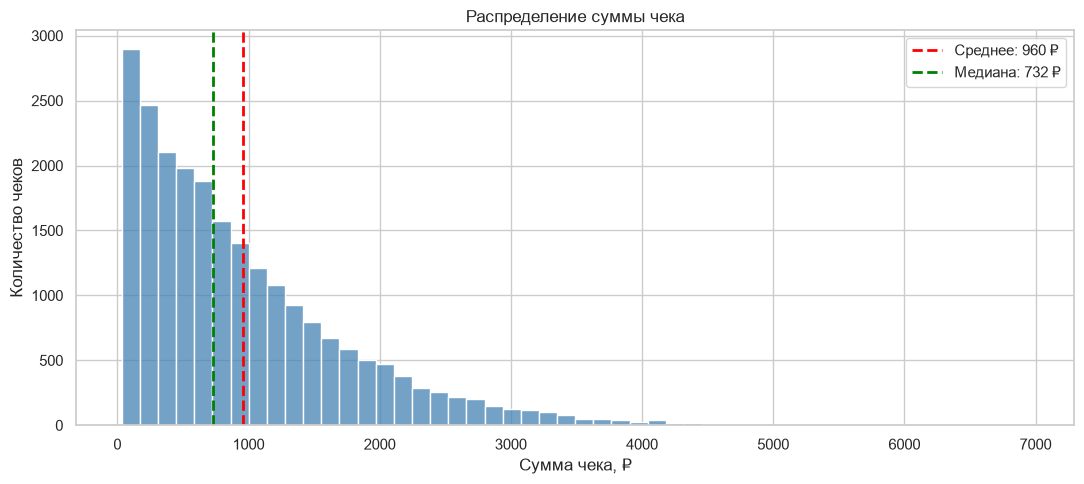

In [24]:
# Анализ распределения чеков и потенциальных выбросов
sns.set_theme(style="whitegrid")

fig, ax = plt.subplots(figsize=(11, 5))

sns.histplot(
    data=sales_checks,
    x="revenue",
    bins=50,
    color="steelblue",
    ax=ax
)

ax.axvline(
    mean_revenue,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Среднее: {mean_revenue:,.0f} ₽"
)

ax.axvline(
    median_revenue,
    color="green",
    linestyle="--",
    linewidth=2,
    label=f"Медиана: {median_revenue:,.0f} ₽"
)

ax.set(
    title="Распределение суммы чека",
    xlabel="Сумма чека, ₽",
    ylabel="Количество чеков"
)

ax.legend()
plt.tight_layout()
plt.show()

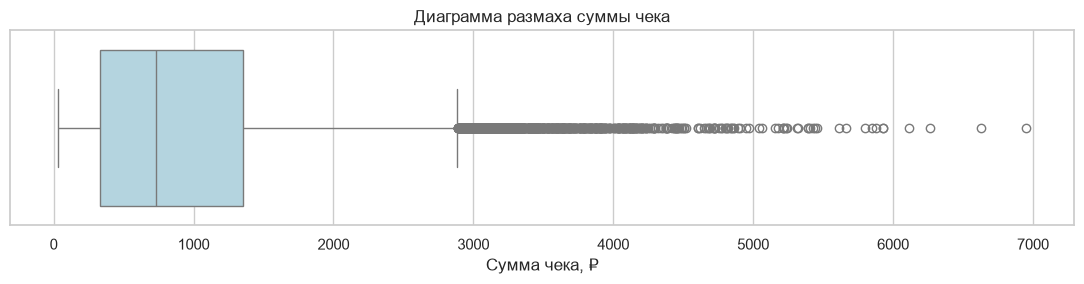

In [25]:
# Boxplot — диаграмма размаха
fig, ax = plt.subplots(figsize=(11, 3))

sns.boxplot(
    data=sales_checks,
    x="revenue",
    color="lightblue",
    ax=ax
)

ax.set(
    title="Диаграмма размаха суммы чека",
    xlabel="Сумма чека, ₽"
)

plt.tight_layout()
plt.show()

In [26]:
# Рассчитаем количество потенциальных выбросов
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outliers = sales_checks[
    (sales_checks["revenue"] < lower_bound) |
    (sales_checks["revenue"] > upper_bound)
]

outlier_summary = pd.DataFrame({
    "Показатель": [
        "Нижняя граница, ₽",
        "Верхняя граница, ₽",
        "Количество потенциальных выбросов",
        "Доля потенциальных выбросов, %",
        "Выручка потенциальных выбросов, ₽",
        "Доля в общей выручке, %"
    ],
    "Значение": [
        lower_bound,
        upper_bound,
        len(outliers),
        len(outliers) / len(sales_checks) * 100,
        outliers["revenue"].sum(),
        outliers["revenue"].sum() / sales_checks["revenue"].sum() * 100
    ]
})

display(outlier_summary.round(2))

,Показатель,Значение
0,"Нижняя граница, ₽",-1202.41
1,"Верхняя граница, ₽",2883.92
2,Количество потенциальных выбросов,787.00
3,"Доля потенциальных выбросов, %",3.45
4,"Выручка потенциальных выбросов, ₽",2789053.91
5,"Доля в общей выручке, %",12.74


### 3.3. Анализ суммы чека по форматам магазинов

Первичный анализ выявил выраженную правостороннюю асимметрию распределения суммы чека и значительную вариативность покупок.

Одно из возможных объяснений — неоднородность форматов магазинов, которые могут обслуживать разные покупательские потребности.

Для проверки этого предположения анализируем распределение суммы чека отдельно по каждому формату: рассчитываем среднее, медиану, стандартное отклонение, квартили, коэффициент вариации и асимметрию.

Это позволит определить, насколько различается покупательское поведение между форматами и целесообразно ли учитывать их при дальнейшей проверке гипотез о скидках.

In [27]:
format_stats = (
    sales_checks
    .groupby("store_format")["revenue"]
    .agg(
        checks_count="count",
        mean="mean",
        median="median",
        std="std",
        q1=lambda x: x.quantile(0.25),
        q3=lambda x: x.quantile(0.75),
        min="min",
        max="max",
        skew="skew"
    )
)

format_stats["iqr"] = (
    format_stats["q3"] - format_stats["q1"]
)

format_stats["cv_pct"] = (
    format_stats["std"] / format_stats["mean"] * 100
)

display(
    format_stats
    .sort_values("mean")
    .round(2)
)

,checks_count,mean,median,std,q1,q3,min,max,skew,iqr,cv_pct
store_format,,,,,,,,,,,
у дома,7686,484.63,352.88,436.58,162.43,663.32,33.48,3430.30,1.79,500.89,90.08
супермаркет,10008,966.47,836.58,666.41,462.76,1320.92,34.11,6115.62,1.12,858.16,68.95
гипермаркет,5096,1666.45,1515.94,1036.79,892.34,2283.79,39.09,6947.38,0.79,1391.45,62.22


#### Вывод по сравнению форматов магазинов

Анализ выявил существенные описательные различия в размерах покупок между форматами торговой сети.

Средний чек составляет 484,63 ₽ в магазинах у дома, 966,47 ₽ в супермаркетах и 1 666,45 ₽ в гипермаркетах. Средний чек гипермаркета в 3,44 раза превышает показатель магазина у дома.

Относительный разброс, измеренный коэффициентом вариации, составляет 90,08%, 68,95% и 62,22% соответственно. Таким образом, при увеличении масштаба торгового формата наблюдается снижение относительной вариативности чеков.

Во всех форматах сохраняется правосторонняя асимметрия распределения, наиболее выраженная в магазинах у дома (1,79).

**Методологический вывод:** формат магазина необходимо учитывать при анализе связи скидок с размером покупательской корзины. Сравнение только общесетевых показателей может скрывать различия между группами и приводить к некорректной бизнес-интерпретации.

Статистическая значимость различий будет оценена на этапе проверки гипотез.

#### 3.4. Анализ потенциальных выбросов с учётом формата магазина

In [28]:
# Рассчитываем индивидуальные границы выбросов
format_bounds = format_stats[["q1", "q3", "iqr"]].copy()

format_bounds["lower_bound"] = (
    format_bounds["q1"] - 1.5 * format_bounds["iqr"]
)

format_bounds["upper_bound"] = (
    format_bounds["q3"] + 1.5 * format_bounds["iqr"]
)

# Добавляем границы к каждому чеку
checks_with_bounds = sales_checks.merge(
    format_bounds[["lower_bound", "upper_bound"]],
    left_on="store_format",
    right_index=True,
    how="left",
    validate="many_to_one"
)

# Определяем потенциальные выбросы внутри формата
checks_with_bounds["is_outlier"] = (
    (checks_with_bounds["revenue"] < checks_with_bounds["lower_bound"]) |
    (checks_with_bounds["revenue"] > checks_with_bounds["upper_bound"])
)

# Сводная таблица
format_outliers = (
    checks_with_bounds
    .groupby("store_format")
    .agg(
        checks_count=("id_чека", "size"),
        outliers_count=("is_outlier", "sum"),
        upper_bound=("upper_bound", "first")
    )
)

format_outliers["outliers_pct"] = (
    format_outliers["outliers_count"]
    / format_outliers["checks_count"]
    * 100
)

display(format_outliers.round(2))

,checks_count,outliers_count,upper_bound,outliers_pct
store_format,,,,
гипермаркет,5096,71,4370.96,1.39
супермаркет,10008,237,2608.16,2.37
у дома,7686,374,1414.66,4.87


#### Вывод по анализу потенциальных выбросов

Применение правила межквартильного размаха отдельно для каждого формата выявило различия в распределении крупных покупок.

В гипермаркетах доля потенциальных выбросов составила 1,39% при верхней границе 4 370,96 ₽, в супермаркетах — 2,37% при границе 2 608,16 ₽, в магазинах у дома — 4,87% при границе 1 414,66 ₽.

Всего по индивидуальным границам форматов выявлено 682 потенциальных выброса против 787 при расчёте единого общесетевого порога.

Результаты подтверждают необходимость учитывать формат магазина при описании распределения суммы чека. Единая граница может классифицировать как нетипичные покупки, которые характерны для гипермаркетов, и не выявлять относительно крупные покупки в магазинах меньшего формата.

Потенциальные выбросы сохраняются в анализе, поскольку их наличие само по себе не свидетельствует об ошибках данных.

#### 3.5. Анализ размера покупательской корзины

Для объяснения различий в суммах чеков между форматами магазинов исследуем количество товарных позиций и общее количество приобретённых единиц товара.

Анализ позволит установить, сопровождается ли увеличение среднего чека ростом количества приобретаемых товаров.

Для каждого формата рассчитываем среднее, медиану и стандартное отклонение количества товарных позиций и единиц товара на чек.

Результаты будут использованы при интерпретации различий в размере покупок и последующей проверке гипотез о скидках.

In [29]:
basket_stats = (
    sales_checks
    .groupby("store_format")
    .agg(
        checks_count=("id_чека", "size"),
        avg_items=("items_count", "mean"),
        median_items=("items_count", "median"),
        std_items=("items_count", "std"),
        avg_units=("units_count", "mean"),
        median_units=("units_count", "median"),
        std_units=("units_count", "std"),
        avg_revenue=("revenue", "mean")
    )
)

display(basket_stats.round(2))

,checks_count,avg_items,median_items,std_items,avg_units,median_units,std_units,avg_revenue
store_format,,,,,,,,
гипермаркет,5096,6.21,6.0,2.90,8.06,8.0,4.03,1666.45
супермаркет,10008,3.57,3.0,1.61,4.64,4.0,2.33,966.47
у дома,7686,1.80,2.0,0.91,2.34,2.0,1.39,484.63


In [30]:
basket_correlations = (
    sales_checks
    .groupby("store_format")
    .apply(
        lambda df: pd.Series({
            "corr_items_revenue": df["items_count"].corr(
                df["revenue"], method="spearman"
            ),
            "corr_units_revenue": df["units_count"].corr(
                df["revenue"], method="spearman"
            )
        }),
        include_groups=False
    )
)

display(basket_correlations.round(3))

,corr_items_revenue,corr_units_revenue
store_format,,
гипермаркет,0.797,0.836
супермаркет,0.695,0.753
у дома,0.627,0.701


#### Вывод по анализу размера покупательской корзины

Анализ показал существенные различия в размере покупательской корзины между форматами магазинов.

Среднее количество приобретённых единиц товара составляет 2,34 в магазинах у дома, 4,64 в супермаркетах и 8,06 в гипермаркетах.

Средний чек и среднее количество единиц товара увеличиваются между форматами в близких пропорциях, что согласуется с предположением о значимой роли размера корзины в формировании выручки на покупку.

Корреляция Спирмена между количеством приобретённых единиц и суммой чека составляет 0,701 для магазинов у дома, 0,753 для супермаркетов и 0,836 для гипермаркетов. Во всех форматах наблюдается положительная монотонная связь.

**Бизнес-интерпретация:** различия среднего чека между форматами связаны не только с денежной стоимостью покупки, но и с количеством приобретаемых товаров. Для анализа скидочной политики необходимо совместно рассматривать сумму чека, размер корзины и валовую прибыль.

Полученные результаты носят описательный характер и не устанавливают причинно-следственных связей.

#### 3.6. Анализ применения скидок по форматам магазинов

На предыдущих этапах выявлены различия в суммах чеков и размерах покупательской корзины между форматами магазинов.

Для последующей проверки статистических гипотез исследуем частоту применения скидок, эффективный размер дисконта и характеристики скидочных покупок.

Основное внимание уделяется покупкам с идентификатором клиента, поскольку предварительный аудит показал, что скидки в датасете применяются только к идентифицированным покупателям.

На этом этапе результаты рассматриваются как описательные характеристики без выводов о причинном влиянии скидок.

In [31]:
# Идентифицированные покупки без скидки
discount_stats = (
    sales_checks
    .groupby("store_format")
    .agg(
        checks_count=("id_чека", "size"),
        identified_checks=("has_customer_id", "sum"),
        discount_checks=("has_discount", "sum"),
        avg_effective_discount=("effective_discount_pct", "mean")
    )
)

discount_stats["discount_checks_pct"] = (
    discount_stats["discount_checks"]
    / discount_stats["checks_count"] * 100
)

discount_stats["identified_checks_pct"] = (
    discount_stats["identified_checks"]
    / discount_stats["checks_count"] * 100
)

display(discount_stats.round(2))

,checks_count,identified_checks,discount_checks,avg_effective_discount,discount_checks_pct,identified_checks_pct
store_format,,,,,,
гипермаркет,5096,2792,2396,1.94,47.02,54.79
супермаркет,10008,5489,4059,1.97,40.56,54.85
у дома,7686,4240,2156,1.97,28.05,55.17


In [32]:
# Идентифицированные покупки со скидкой
identified_checks = sales_checks.loc[
    sales_checks["has_customer_id"]
].copy()

discount_comparison = (
    identified_checks
    .groupby(["store_format", "has_discount"])
    .agg(
        checks_count=("id_чека", "size"),
        mean_revenue=("revenue", "mean"),
        median_revenue=("revenue", "median"),
        std_revenue=("revenue", "std"),
        mean_units=("units_count", "mean"),
        mean_gross_profit=("gross_profit", "mean"),
        mean_effective_discount=("effective_discount_pct", "mean")
    )
)

display(discount_comparison.round(2))

checks_count  mean_revenue  median_revenue  \
store_format has_discount                                               
гипермаркет  False                  396        915.53          683.83   
             True                  2396       1764.90         1607.90   
супермаркет  False                 1430        719.53          579.32   
             True                  4059       1037.09          906.58   
у дома       False                 2084        428.36          289.20   
             True                  2156        531.34          408.81   

                           std_revenue  mean_units  mean_gross_profit  \
store_format has_discount                                               
гипермаркет  False              791.88        4.25             254.57   
             True              1013.40        8.70             438.97   
супермаркет  False              591.05        3.41             200.30   
             True               664.58        5.11             253.19   
у дома       False              404.87        2.04             118.24   
             True               441.38        2.68             123.24   

                           mean_effective_discount  
store_format has_discount                           
гипермаркет  False                            0.00  
             True                             4.12  
супермаркет  False                            0.00  
             True                             4.87  
у дома       False                            0.00  
             True                             7.01

In [33]:
margin_comparison = (
    identified_checks
    .groupby(["store_format", "has_discount"])
    .agg(
        revenue=("revenue", "sum"),
        gross_profit=("gross_profit", "sum")
    )
)

margin_comparison["gross_margin_pct"] = (
    margin_comparison["gross_profit"]
    / margin_comparison["revenue"] * 100
)

display(margin_comparison.round(2))

revenue  gross_profit  gross_margin_pct
store_format has_discount                                            
гипермаркет  False          362550.11     100808.90             27.81
             True          4228696.20    1051782.34             24.87
супермаркет  False         1028926.66     286423.01             27.84
             True          4209565.67    1027691.00             24.41
у дома       False          892698.45     246414.33             27.60
             True          1145560.84     265713.91             23.20

#### Вывод по анализу скидок и покупательской корзины

Анализ идентифицированных покупателей выявил различия в частоте применения скидок и финансовых характеристиках покупок между форматами магазинов.

Доля скидочных чеков среди идентифицированных покупок составляет 50,85% в магазинах у дома, 73,95% в супермаркетах и 85,82% в гипермаркетах.

Во всех форматах средний скидочный чек превышает средний нескиточный: на 24,0%, 44,1% и 92,8% соответственно. Одновременно скидочные покупки характеризуются большим количеством приобретённых товаров.

Однако различия в оценочной валовой прибыли выражены слабее: +4,23% в магазинах у дома, +26,41% в супермаркетах и +72,44% в гипермаркетах.

Предварительная оценка показывает, что относительная валовая маржа скидочных покупок ниже во всех форматах.

**Бизнес-интерпретация:** более высокая выручка скидочных покупок не сопровождается пропорциональным увеличением валовой прибыли. Наиболее заметное расхождение наблюдается в магазинах у дома.

Полученные результаты указывают на необходимость проверить статистическую значимость различий и дополнительно учесть размер корзины и ассортиментный состав покупок.

Выявленные зависимости являются наблюдательными и не доказывают причинного влияния скидок.

#### 3.7. Связь размера корзины с наличием скидки

Поскольку скидочный чек определяется наличием хотя бы одной позиции со скидкой, вероятность попадания чека в скидочную группу может зависеть от количества приобретаемых товаров.

Для проверки этой особенности исследуем долю чеков со скидкой в зависимости от количества товарных позиций отдельно по форматам магазинов.

Анализ проводится только среди идентифицированных покупателей, поскольку скидки в датасете не встречаются у покупок без идентификатора клиента.

In [34]:
# Группируем количество позиций в корзине
bins = [0, 1, 2, 3, 5, 8, float("inf")]
labels = ["1", "2", "3", "4–5", "6–8", "9+"]

identified_checks["basket_size_group"] = pd.cut(
    identified_checks["items_count"],
    bins=bins,
    labels=labels
)

# Частота скидочных чеков по размеру корзины и формату
basket_discount = (
    identified_checks
    .groupby(
        ["store_format", "basket_size_group"],
        observed=True
    )
    .agg(
        checks_count=("id_чека", "size"),
        discount_rate=("has_discount", "mean")
    )
    .reset_index()
)

basket_discount["discount_rate_pct"] = (
    basket_discount["discount_rate"] * 100
)

display(
    basket_discount[
        ["store_format", "basket_size_group",
         "checks_count", "discount_rate_pct"]
    ].round(2)
)

,store_format,basket_size_group,checks_count,discount_rate_pct
0,гипермаркет,1,185,33.51
1,гипермаркет,2,181,60.77
2,гипермаркет,3,189,74.07
3,гипермаркет,4–5,596,87.25
4,гипермаркет,6–8,986,93.81
5,гипермаркет,9+,655,97.56
6,супермаркет,1,676,37.43
7,супермаркет,2,684,60.96
8,супермаркет,3,1368,73.10
9,супермаркет,4–5,2023,83.74


#### Вывод по связи размера корзины с наличием скидки

Анализ выявил устойчивую положительную связь между количеством товарных позиций в чеке и долей покупок, содержащих хотя бы одну скидочную позицию.

Среди идентифицированных покупателей доля скидочных чеков с одной позицией составляет 33,51–37,43% в зависимости от формата. При двух позициях показатель увеличивается до 57,62–60,96%, при трёх — до 68,59–74,07%.

При сопоставимом количестве товарных позиций различия между форматами заметно меньше, чем при сравнении общей доли скидочных чеков.

**Методологический вывод:** вероятность классификации чека как скидочного связана с размером корзины. Следовательно, простое сравнение скидочных и нескиточных покупок может отражать не только различия скидочной политики, но и различия в количестве приобретаемых товаров.

При проверке гипотез необходимо учитывать формат магазина и размер корзины. Выявленная зависимость не интерпретируется как доказательство того, что скидки стимулируют увеличение количества покупок или товаров в чеке.

### Этап 4. Проверка статистических гипотез

#### 4.1. H1 — различия среднего чека между скидочными и нескиточными покупками

**Бизнес-вопрос:** различается ли средняя сумма чека среди идентифицированных покупателей в зависимости от наличия скидочных товарных позиций с учётом формата магазина?

**H₀:** средние суммы скидочных и нескиточных чеков равны внутри рассматриваемого формата.

**H₁:** средние суммы скидочных и нескиточных чеков различаются.

Проверка проводится отдельно для каждого формата магазина с использованием двустороннего t-критерия Уэлча. Уровень значимости — 0,05.

Выбор критерия обусловлен сравнением средних двух групп, различающихся по численности и стандартному отклонению.

Для трёх сравнений предусмотрена корректировка множественных проверок методом Холма.

Полученные результаты характеризуют наблюдаемые различия между группами, но не причинный эффект скидок. Дополнительная проверка с учётом размера корзины будет проведена в H2.

In [35]:
# Подготавливаем описание сравниваемых групп
h1_group_stats = (
    identified_checks
    .groupby(["store_format", "has_discount"])
    .agg(
        n=("revenue", "size"),
        mean=("revenue", "mean"),
        median=("revenue", "median"),
        std=("revenue", "std"),
        skew=("revenue", "skew")
    )
)

display(h1_group_stats.round(2))

n     mean   median      std  skew
store_format has_discount                                       
гипермаркет  False          396   915.53   683.83   791.88  1.29
             True          2396  1764.90  1607.90  1013.40  0.82
супермаркет  False         1430   719.53   579.32   591.05  1.43
             True          4059  1037.09   906.58   664.58  1.16
у дома       False         2084   428.36   289.20   404.87  2.05
             True          2156   531.34   408.81   441.38  1.61

In [36]:
# Проверяем минимальный размер группы
min_group_size = h1_group_stats["n"].min()

print("Минимальный размер группы:", min_group_size)

# Проверяем наличие обеих групп в каждом формате
group_counts = identified_checks.groupby(
    ["store_format", "has_discount"]
).size().unstack(fill_value=0)

display(group_counts)

assert (group_counts > 1).all().all(), (
    "Для одного из форматов недостаточно наблюдений"
)

Минимальный размер группы: 396


has_discount,False,True
store_format,,
гипермаркет,396,2396
супермаркет,1430,4059
у дома,2084,2156


#### Проверка H1 с использованием t-критерия Уэлча

Для каждого формата магазина проводится двусторонняя проверка равенства средних сумм чеков идентифицированных покупателей со скидкой и без скидки.

Используется t-критерий Уэлча, допускающий различия дисперсий и размеров сравниваемых групп.

Помимо статистики критерия и p-value рассчитываются абсолютная и относительная разница средних, а также 95%-ный доверительный интервал разницы.

Для контроля семейной вероятности ложноположительного вывода при трёх сравнениях применяется поправка Холма.

Результаты рассматриваются как разведочный анализ наблюдаемых различий, а не оценка причинного эффекта скидок.

In [37]:
h1_results = []

for store_format, group in identified_checks.groupby("store_format"):

    # Формируем две сравниваемые выборки
    discount = group.loc[group["has_discount"], "revenue"]
    no_discount = group.loc[~group["has_discount"], "revenue"]

    # Двусторонний критерий Уэлча
    test = stats.ttest_ind(
        discount,
        no_discount,
        equal_var=False,
        alternative="two-sided"
    )

    # Разница средних
    mean_diff = discount.mean() - no_discount.mean()

    # Относительная разница
    relative_diff = mean_diff / no_discount.mean() * 100

    # Стандартная ошибка разницы
    se = np.sqrt(
        discount.var(ddof=1) / len(discount)
        + no_discount.var(ddof=1) / len(no_discount)
    )

    # Степени свободы Уэлча
    v1 = discount.var(ddof=1) / len(discount)
    v0 = no_discount.var(ddof=1) / len(no_discount)

    df_welch = (v1 + v0) ** 2 / (
        v1**2 / (len(discount) - 1)
        + v0**2 / (len(no_discount) - 1)
    )

    # 95%-ный доверительный интервал
    ci_low, ci_high = stats.t.interval(
        confidence=0.95,
        df=df_welch,
        loc=mean_diff,
        scale=se
    )

    h1_results.append({
        "Формат": store_format,
        "Разница средних, ₽": mean_diff,
        "Разница, %": relative_diff,
        "t-статистика": test.statistic,
        "p-value": test.pvalue,
        "CI 95% нижняя, ₽": ci_low,
        "CI 95% верхняя, ₽": ci_high
    })

h1_results = pd.DataFrame(h1_results)

# Корректировка трёх p-value методом Холма
h1_results["p-value Holm"] = multipletests(
    h1_results["p-value"],
    alpha=0.05,
    method="holm"
)[1]

h1_results["Статистически значимо"] = (
    h1_results["p-value Holm"] < 0.05
)

display(
    h1_results.style.format({
        "p-value": "{:.2e}",
        "p-value Holm": "{:.2e}",
        "Разница средних, ₽": "{:.2f}",
        "Разница, %": "{:.2f}"
    })
)

,Формат,"Разница средних, ₽","Разница, %",t-статистика,p-value,"CI 95% нижняя, ₽","CI 95% верхняя, ₽",p-value Holm,Статистически значимо
0,гипермаркет,849.37,92.77,18.935117,1.22e-63,761.280883,937.454449,3.67e-63,True
1,супермаркет,317.57,44.14,16.899771,4.45e-61,280.719300,354.410988,8.90e-61,True
2,у дома,102.98,24.04,7.921022,2.99e-15,77.490013,128.466017,2.99e-15,True


#### Результаты проверки гипотезы H1

Для сравнения средних сумм чеков идентифицированных покупателей со скидкой и без скидки применён двусторонний t-критерий Уэлча отдельно для каждого формата магазина.

Во всех трёх форматах нулевая гипотеза о равенстве средних отвергнута при уровне значимости 0,05, включая корректировку множественных сравнений методом Холма.

Наблюдаемая разница средних составила:

- Магазины у дома: +102,98 ₽ (+24,04%), 95% ДИ [77,49; 128,47] ₽.
- Супермаркеты: +317,57 ₽ (+44,14%), 95% ДИ [280,72; 354,41] ₽.
- Гипермаркеты: +849,37 ₽ (+92,77%), 95% ДИ [761,28; 937,45] ₽.

Наибольшая абсолютная и относительная разница наблюдается в гипермаркетах.

**Статистический вывод:** скидочные и нескиточные покупки характеризуются различными средними суммами чека во всех форматах. Результаты значимы в рамках применённого критерия и его предпосылок.

**Бизнес-интерпретация:** более высокий средний чек скидочной группы не означает, что скидки являются причиной увеличения суммы покупки. Предыдущий анализ показал, что скидочные чеки содержат больше товаров, а вероятность классификации чека как скидочного увеличивается с размером корзины.

**Ограничения:** сравнение не учитывает размер корзины, товарный состав и возможную зависимость повторных покупок одного клиента. Поэтому результат рассматривается как первоначальная оценка наблюдаемых различий, требующая дополнительной проверки.

#### 4.2. H2 — связь скидок с суммой чека при учёте размера корзины

Первичная проверка H1 выявила статистически значимые различия средних чеков между скидочными и нескиточными покупками.

Однако разведочный анализ показал, что вероятность наличия скидки увеличивается с количеством товарных позиций в чеке. Поэтому часть наблюдаемой разницы может быть обусловлена размером корзины.

Для уточнения результата необходимо оценить наличие сопоставимых скидочных и нескиточных покупок при одинаковом количестве товарных позиций внутри форматов магазинов.

После проверки сопоставимости будет использована статистическая модель, учитывающая размер корзины и формат магазина.

In [38]:
# Количество скидочных и нескиточных чеков
# при одинаковом размере корзины

overlap_table = (
    identified_checks
    .groupby(
        ["store_format", "items_count", "has_discount"]
    )
    .size()
    .unstack(fill_value=0)
    .rename(columns={
        False: "without_discount",
        True: "with_discount"
    })
)

# Доля скидочных чеков внутри каждой группы
overlap_table["discount_share_pct"] = (
    overlap_table["with_discount"]
    / (
        overlap_table["without_discount"]
        + overlap_table["with_discount"]
    )
    * 100
)

display(overlap_table.round(2))

has_discount              without_discount  with_discount  discount_share_pct
store_format items_count                                                     
гипермаркет  1                         123             62               33.51
             2                          71            110               60.77
             3                          49            140               74.07
             4                          37            141               79.21
             5                          39            379               90.67
             6                          32            373               92.10
             7                          19            278               93.60
             8                          10            274               96.48
             9                          11            218               95.20
             10                          4            198               98.02
             11                          1            143               99.31
             12                          0             80              100.00
супермаркет  1                         423            253               37.43
             2                         267            417               60.96
             3                         368           1000               73.10
             4                         226            976               81.20
             5                         103            718               87.45
             6                          33            456               93.25
             7                          10            239               95.98
у дома       1                        1258            736               36.91
             2                         551            749               57.62
             3                         218            476               68.59
             4                          57            195               77.38

#### Подготовка сопоставимых групп для проверки H2

Анализ показал, что вероятность наличия скидочной позиции возрастает с количеством товарных позиций в чеке.

Для уменьшения влияния различий в размере корзины основная проверка H2 проводится внутри комбинаций формата магазина и количества товарных позиций.

В анализ включаются только комбинации, содержащие не менее 30 скидочных и 30 нескиточных чеков. Порог выбран как практическое ограничение минимальной численности групп; он не гарантирует их полной сопоставимости.

Такое ограничение позволяет избежать сравнений, основанных преимущественно на экстраполяции модели. Результаты H2 будут относиться к выбранной области сопоставимости, а не ко всем покупкам сети.

Ограничение не применяется к исходным данным и не связано с удалением статистических выбросов.

In [39]:
# Минимальное количество чеков в каждой группе
min_n = 30

# Находим сопоставимые комбинации
valid_strata = overlap_table.loc[
    (overlap_table["without_discount"] >= min_n)
    & (overlap_table["with_discount"] >= min_n)
].index

# Формируем аналитическую выборку H2
h2_data = identified_checks.set_index(
    ["store_format", "items_count"]
)

h2_data = (
    h2_data.loc[h2_data.index.isin(valid_strata)]
    .reset_index()
    .copy()
)

# Сравниваем размеры исходной и ограниченной выборок
h2_sample_summary = pd.DataFrame({
    "Показатель": [
        "Идентифицированных чеков всего",
        "Чеков в выборке H2",
        "Исключено из H2",
        "Доля сохранённых чеков, %"
    ],
    "Значение": [
        len(identified_checks),
        len(h2_data),
        len(identified_checks) - len(h2_data),
        len(h2_data) / len(identified_checks) * 100
    ]
})

display(h2_sample_summary.round(2))

,Показатель,Значение
0,Идентифицированных чеков всего,12521.00
1,Чеков в выборке H2,11036.00
2,Исключено из H2,1485.00
3,"Доля сохранённых чеков, %",88.14


In [40]:
h2_group_summary = (
    h2_data
    .groupby(["store_format", "has_discount"])
    .agg(
        checks_count=("id_чека", "size"),
        mean_revenue=("revenue", "mean"),
        mean_items=("items_count", "mean")
    )
)

display(h2_group_summary.round(2))

print(
    "Количество сопоставимых комбинаций:",
    len(valid_strata)
)

checks_count  mean_revenue  mean_items
store_format has_discount                                        
гипермаркет  False                  351        774.25        2.70
             True                  1205       1153.42        4.48
супермаркет  False                 1420        712.83        2.59
             True                  3820        988.92        3.75
у дома       False                 2084        428.36        1.56
             True                  2156        531.34        2.06

Количество сопоставимых комбинаций: 16


#### Регрессионная проверка H2

Для оценки связи наличия скидочной позиции с суммой чека с учётом размера корзины применяется линейная регрессия OLS.

Модель включает фиксированные эффекты комбинаций формата магазина и количества товарных позиций, а также взаимодействие признака скидки с форматом магазина.

Таким образом, сравнение проводится с учётом наблюдаемых различий в размере корзин между форматами.

Для учёта повторных покупок идентифицированных клиентов используются стандартные ошибки с кластеризацией по `customer_id`.

Результаты интерпретируются как скорректированные статистические ассоциации, а не как причинный эффект скидки.

In [41]:
# Создаём независимую рабочую копию
h2_model_data = h2_data.copy()

# Числовой признак скидки
h2_model_data["discount_flag"] = (
    h2_model_data["has_discount"].astype(int)
)

# Устанавливаем порядок форматов
format_order = ["у дома", "супермаркет", "гипермаркет"]

h2_model_data["store_format"] = pd.Categorical(
    h2_model_data["store_format"],
    categories=format_order
)

# Комбинация формата и размера корзины
h2_model_data["basket_stratum"] = (
    h2_model_data["store_format"].astype(str)
    + "_"
    + h2_model_data["items_count"].astype(str)
)

# Проверяем наличие идентификаторов клиентов
assert h2_model_data["customer_id"].notna().all()

print("Наблюдений:", len(h2_model_data))
print(
    "Уникальных клиентов:",
    h2_model_data["customer_id"].nunique()
)
print(
    "Комбинаций формата и корзины:",
    h2_model_data["basket_stratum"].nunique()
)

Наблюдений: 11036
Уникальных клиентов: 4400
Комбинаций формата и корзины: 16


In [42]:
# Исправленная модель
h2_model = smf.ols(
    formula=(
        "revenue ~ C(basket_stratum) "
        "+ discount_flag:C(store_format)"
    ),
    data=h2_model_data
).fit(
    cov_type="cluster",
    cov_kwds={
        "groups": h2_model_data["customer_id"]
    }
)

print(h2_model.summary())

                            OLS Regression Results                            
Dep. Variable:                revenue   R-squared:                       0.459
Model:                            OLS   Adj. R-squared:                  0.458
Method:                 Least Squares   F-statistic:                     536.1
Date:                Sun, 18 Oct 2026   Prob (F-statistic):               0.00
Time:                        21:44:01   Log-Likelihood:                -83219.
No. Observations:               11036   AIC:                         1.665e+05
Df Residuals:                   11017   BIC:                         1.666e+05
Df Model:                          18                                         
Covariance Type:              cluster                                         
                                                 coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------------

In [43]:
# Проверяем ранг матрицы признаков
X = h2_model.model.exog

matrix_rank = np.linalg.matrix_rank(X)
n_columns = X.shape[1]

print("Количество столбцов матрицы:", n_columns)
print("Ранг матрицы:", matrix_rank)
print("Полный ранг:", matrix_rank == n_columns)

# Проверяем наличие некорректных коэффициентов
print(
    "Все коэффициенты конечны:",
    np.isfinite(h2_model.params).all()
)

print(
    "Все стандартные ошибки конечны:",
    np.isfinite(h2_model.bse).all()
)

print(
    "Все p-value конечны:",
    np.isfinite(h2_model.pvalues).all()
)

Количество столбцов матрицы: 19
Ранг матрицы: 19
Полный ранг: True
Все коэффициенты конечны: True
Все стандартные ошибки конечны: True
Все p-value конечны: True


#### Спецификация регрессионной модели

Для учёта различий в размере корзины используются фиксированные эффекты комбинаций формата магазина и количества товарных позиций.

Наличие скидки включается во взаимодействии с форматом магазина, что позволяет оценивать отдельные скорректированные различия для каждого формата.

Самостоятельный основной эффект формата не включается, поскольку информация о нём уже содержится в фиксированных эффектах комбинаций. Это позволяет избежать точной линейной зависимости между соответствующими признаками.

Стандартные ошибки рассчитываются с кластеризацией по идентификатору клиента для учёта возможной зависимости повторных покупок.

In [44]:
# Выбираем коэффициенты связи скидки с суммой чека
mask = h2_model.params.index.str.startswith(
    "discount_flag:C(store_format)"
)

h2_results = pd.DataFrame({
    "coefficient": h2_model.params[mask],
    "std_error": h2_model.bse[mask],
    "p_value": h2_model.pvalues[mask]
})

# Доверительные интервалы
ci = h2_model.conf_int().loc[h2_results.index]

h2_results["ci_low"] = ci[0]
h2_results["ci_high"] = ci[1]

# Поправка Холма
h2_results["p_holm"] = multipletests(
    h2_results["p_value"],
    alpha=0.05,
    method="holm"
)[1]

h2_results["significant_holm"] = (
    h2_results["p_holm"] < 0.05
)

display(
    h2_results.style.format({
        "coefficient": "{:.2f}",
        "std_error": "{:.2f}",
        "p_value": "{:.3e}",
        "ci_low": "{:.2f}",
        "ci_high": "{:.2f}",
        "p_holm": "{:.3e}"
    })
)

,coefficient,std_error,p_value,ci_low,ci_high,p_holm,significant_holm
discount_flag:C(store_format)[у дома],-28.70,11.52,1.270e-02,-51.27,-6.13,2.540e-02,True
discount_flag:C(store_format)[супермаркет],-37.94,15.50,1.439e-02,-68.33,-7.56,2.540e-02,True
discount_flag:C(store_format)[гипермаркет],-97.27,35.96,6.829e-03,-167.74,-26.79,2.049e-02,True


#### Итог проверки гипотезы H2

Регрессионный анализ проведён на 11 036 чеках с учётом формата магазина и количества товарных позиций. Для оценки неопределённости использованы стандартные ошибки с кластеризацией по клиентам.

После корректировки множественных сравнений методом Холма все три коэффициента остались статистически значимыми при уровне значимости 0,05:

- Магазины у дома: −28,70 ₽, p-value Holm = 0,0254.
- Супермаркеты: −37,94 ₽, p-value Holm = 0,0254.
- Гипермаркеты: −97,27 ₽, p-value Holm = 0,0205.

Нулевая гипотеза об отсутствии условной связи между признаком скидки и суммой чека отвергается во всех трёх форматах.

**Статистический вывод:** при одинаковом количестве товарных позиций и с учётом формата скидочные чеки имеют меньшую ожидаемую сумму, чем нескиточные.

**Бизнес-вывод:** наблюдаемый в H1 более высокий средний чек скидочных покупок не является достаточным доказательством результативности скидочной политики. Значительная часть исходного различия связана с неодинаковым размером корзин.

Полученные коэффициенты характеризуют статистическую ассоциацию в ограниченной аналитической выборке, а не причинный эффект предоставления скидки.

#### 4.3. H3 — различия валовой прибыли с учётом размера корзины

**Бизнес-вопрос:** существует ли статистически значимая связь между наличием скидочной позиции и оценочной валовой прибылью на чек после учёта формата магазина и количества товарных позиций?

**H₀:** скорректированная разница валовой прибыли между скидочными и нескиточными покупками равна нулю.

**H₁:** скорректированная разница валовой прибыли отлична от нуля.

Для проверки используется линейная регрессия OLS с фиксированными эффектами комбинаций формата и количества товарных позиций. Стандартные ошибки кластеризуются по идентификатору клиента.

Используется та же выборка, что и в H2, что позволяет сопоставлять скорректированные различия выручки и валовой прибыли.

Поскольку исторические закупочные цены недоступны, исследуемая валовая прибыль является оценочной.

In [45]:
# H3: модель валовой прибыли
h3_model = smf.ols(
    formula=(
        "gross_profit ~ C(basket_stratum) "
        "+ discount_flag:C(store_format)"
    ),
    data=h2_model_data
).fit(
    cov_type="cluster",
    cov_kwds={
        "groups": h2_model_data["customer_id"]
    }
)

print(h3_model.summary())

                            OLS Regression Results                            
Dep. Variable:           gross_profit   R-squared:                       0.456
Model:                            OLS   Adj. R-squared:                  0.455
Method:                 Least Squares   F-statistic:                     546.9
Date:                Sun, 18 Oct 2026   Prob (F-statistic):               0.00
Time:                        21:44:02   Log-Likelihood:                -68199.
No. Observations:               11036   AIC:                         1.364e+05
Df Residuals:                   11017   BIC:                         1.366e+05
Df Model:                          18                                         
Covariance Type:              cluster                                         
                                                 coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------------

In [46]:
# Проверяем техническую корректность модели
X_h3 = h3_model.model.exog

print("Полный ранг:",
      np.linalg.matrix_rank(X_h3) == X_h3.shape[1])

print("Коэффициенты конечны:",
      np.isfinite(h3_model.params).all())

print("Стандартные ошибки конечны:",
      np.isfinite(h3_model.bse).all())

Полный ранг: True
Коэффициенты конечны: True
Стандартные ошибки конечны: True


In [47]:
# Выбираем коэффициенты скидки
mask_h3 = h3_model.params.index.str.startswith(
    "discount_flag:C(store_format)"
)

h3_results = pd.DataFrame({
    "coefficient": h3_model.params[mask_h3],
    "std_error": h3_model.bse[mask_h3],
    "p_value": h3_model.pvalues[mask_h3]
})

ci_h3 = h3_model.conf_int().loc[h3_results.index]

h3_results["ci_low"] = ci_h3[0]
h3_results["ci_high"] = ci_h3[1]

# Корректировка Холма
h3_results["p_holm"] = multipletests(
    h3_results["p_value"],
    alpha=0.05,
    method="holm"
)[1]

h3_results["significant_holm"] = (
    h3_results["p_holm"] < 0.05
)

display(h3_results.round(4))

,coefficient,std_error,p_value,ci_low,ci_high,p_holm,significant_holm
discount_flag:C(store_format)[у дома],-30.6469,2.9271,0.0,-36.3839,-24.9099,0.0,True
discount_flag:C(store_format)[супермаркет],-40.6184,4.1085,0.0,-48.6710,-32.5659,0.0,True
discount_flag:C(store_format)[гипермаркет],-58.8702,9.9177,0.0,-78.3086,-39.4319,0.0,True


In [48]:
display(
    h3_results.style.format({
        "coefficient": "{:.2f}",
        "std_error": "{:.2f}",
        "p_value": "{:.3e}",
        "ci_low": "{:.2f}",
        "ci_high": "{:.2f}",
        "p_holm": "{:.3e}"
    })
)

,coefficient,std_error,p_value,ci_low,ci_high,p_holm,significant_holm
discount_flag:C(store_format)[у дома],-30.65,2.93,1.186e-25,-36.38,-24.91,3.557e-25,True
discount_flag:C(store_format)[супермаркет],-40.62,4.11,4.769e-23,-48.67,-32.57,9.538e-23,True
discount_flag:C(store_format)[гипермаркет],-58.87,9.92,2.923e-09,-78.31,-39.43,2.923e-09,True


#### Итог проверки гипотезы H3

Для оценки связи скидок с валовой прибылью на чек построена регрессионная модель OLS с фиксированными эффектами формата магазина и количества товарных позиций. Анализ проведён на 11 036 чеках, стандартные ошибки кластеризованы по идентификатору клиента.

После корректировки множественных сравнений методом Холма во всех форматах обнаружена статистически значимая отрицательная связь между наличием скидочной позиции и оценочной валовой прибылью:

- Магазины у дома: −30,65 ₽, p-value Holm = 3,557 × 10⁻²⁵.
- Супермаркеты: −40,62 ₽, p-value Holm = 9,538 × 10⁻²³.
- Гипермаркеты: −58,87 ₽, p-value Holm = 2,923 × 10⁻⁹.

Нулевая гипотеза об отсутствии скорректированной разницы отвергается во всех трёх форматах.

**Бизнес-вывод:** более высокий средний чек и абсолютная валовая прибыль скидочных покупок, обнаруженные при первичном анализе, не являются достаточными показателями эффективности скидочной политики. После учёта размера корзины наблюдается отрицательная связь скидок как с выручкой, так и с валовой прибылью на чек.

Результаты не доказывают причинного влияния скидок и не позволяют оценить изменение общей прибыли сети при отмене или изменении скидочной политики.

#### 4.4. H4 — различия распределений валовой прибыли между форматами магазинов

**Бизнес-вопрос:** различается ли распределение оценочной валовой прибыли на чек между форматами торговой сети?

**H₀:** распределения валовой прибыли на чек одинаковы во всех форматах магазинов.

**H₁:** хотя бы одно распределение отличается.

Для сравнения трёх групп используется непараметрический критерий Краскела — Уоллиса, основанный на рангах наблюдений.

Выбор обусловлен выраженной асимметрией распределений денежных показателей и наличием крупных покупок.

Перед статистической проверкой рассчитываются описательные характеристики валовой прибыли по форматам.

In [49]:
# Описательная статистика валовой прибыли
h4_group_stats = (
    sales_checks
    .groupby("store_format")["gross_profit"]
    .agg(
        n="size",
        mean="mean",
        median="median",
        std="std",
        q1=lambda x: x.quantile(0.25),
        q3=lambda x: x.quantile(0.75),
        skew="skew"
    )
)

display(h4_group_stats.round(2))

,n,mean,median,std,q1,q3,skew
store_format,,,,,,,
гипермаркет,5096,438.80,399.08,276.35,230.86,602.39,0.86
супермаркет,10008,253.88,220.31,176.89,122.08,346.39,1.20
у дома,7686,127.88,92.92,116.55,44.58,173.36,1.90


#### Описательные характеристики валовой прибыли по форматам

Средняя оценочная валовая прибыль на чек составляет 127,88 ₽ в магазинах у дома, 253,88 ₽ в супермаркетах и 438,80 ₽ в гипермаркетах.

Медианные значения также последовательно увеличиваются с размером торгового формата: 92,92 ₽, 220,31 ₽ и 399,08 ₽ соответственно.

Все три распределения характеризуются положительной асимметрией, наиболее выраженной в магазинах у дома (1,90). Стандартное отклонение увеличивается от 116,55 ₽ до 276,35 ₽.

Наблюдаемые различия согласуются с ранее выявленными особенностями размера покупательской корзины.

При этом более высокая валовая прибыль на чек не свидетельствует о большей общей экономической эффективности торгового формата, поскольку анализ не учитывает операционные расходы и масштаб торговых точек.

Для формальной оценки различий распределений применяется критерий Краскела — Уоллиса.

In [50]:
# Формируем выборки валовой прибыли по форматам
h4_groups = {
    store_format: group["gross_profit"].to_numpy()
    for store_format, group in sales_checks.groupby("store_format")
}

# Критерий Краскела — Уоллиса
h4_test = stats.kruskal(*h4_groups.values())

print(f"H-статистика: {h4_test.statistic:.4f}")
print(f"p-value: {h4_test.pvalue:.3e}")

print(
    "Решение:",
    "Отвергаем H0" if h4_test.pvalue < 0.05
    else "Недостаточно оснований отвергнуть H0"
)

H-статистика: 6284.9311
p-value: 0.000e+00
Решение: Отвергаем H0


In [51]:
# Размер эффекта epsilon-squared
n = sum(len(group) for group in h4_groups.values())
k = len(h4_groups)

epsilon_sq = max(
    0,
    (h4_test.statistic - k + 1) / (n - k)
)

print(f"Количество наблюдений: {n}")
print(f"Количество групп: {k}")
print(f"Epsilon-squared: {epsilon_sq:.4f}")

Количество наблюдений: 22790
Количество групп: 3
Epsilon-squared: 0.2757


#### Результаты критерия Краскела — Уоллиса

Для проверки различий распределений оценочной валовой прибыли на чек между тремя форматами магазинов применён критерий Краскела — Уоллиса.

Получены следующие результаты:

- H-статистика = 6 284,93.
- p-value < 0,001.
- Размер эффекта epsilon-squared = 0,2757.
- Количество наблюдений = 22 790.

При уровне значимости 0,05 нулевая гипотеза об одинаковых распределениях отвергается.

Размер эффекта указывает на выраженные межгрупповые различия на ранговой шкале. Полученный результат согласуется с описательной статистикой, согласно которой средняя и медианная прибыль увеличиваются от магазинов у дома к гипермаркетам.

**Бизнес-интерпретация:** формат магазина является важным фактором сегментации при исследовании финансового результата покупки. Использование единого ориентира валовой прибыли на чек для всей сети может скрывать существенные различия между форматами.

Результат не свидетельствует о большей общей экономической эффективности гипермаркетов, поскольку не учитывает операционные расходы и масштаб торговых точек.

Для определения различий между конкретными парами форматов необходимы попарные статистические проверки.

#### Попарные сравнения форматов магазинов

После выявления статистически значимых различий распределений валовой прибыли между форматами проводится попарный анализ.

Используется двусторонний критерий Манна — Уитни. Для трёх попарных сравнений применяется корректировка p-value методом Холма.

Помимо статистической значимости рассчитывается ранговый размер эффекта, отражающий вероятность того, что прибыль случайно выбранного чека одного формата будет выше прибыли чека другого формата, с учётом возможных совпадений значений.

In [52]:
h4_pairwise_results = []

for format_a, format_b in combinations(h4_groups.keys(), 2):
    a = h4_groups[format_a]
    b = h4_groups[format_b]

    # Двусторонний критерий Манна — Уитни
    test = stats.mannwhitneyu(
        a,
        b,
        alternative="two-sided",
        method="asymptotic"
    )

    # Вероятность превосходства с половинным весом совпадений
    probability_superiority = (
        test.statistic / (len(a) * len(b))
    )

    # Ранговая корреляция rank-biserial
    rank_biserial = 2 * probability_superiority - 1

    h4_pairwise_results.append({
        "Формат A": format_a,
        "Формат B": format_b,
        "n_A": len(a),
        "n_B": len(b),
        "U": test.statistic,
        "p_value": test.pvalue,
        "probability_superiority": probability_superiority,
        "rank_biserial": rank_biserial
    })

h4_pairwise_results = pd.DataFrame(h4_pairwise_results)

# Поправка Холма
h4_pairwise_results["p_holm"] = multipletests(
    h4_pairwise_results["p_value"],
    method="holm"
)[1]

h4_pairwise_results["significant"] = (
    h4_pairwise_results["p_holm"] < 0.05
)

display(
    h4_pairwise_results.style.format({
        "U": "{:.0f}",
        "p_value": "{:.3e}",
        "p_holm": "{:.3e}",
        "probability_superiority": "{:.3f}",
        "rank_biserial": "{:.3f}"
    })
)

,Формат A,Формат B,n_A,n_B,U,p_value,probability_superiority,rank_biserial,p_holm,significant
0,гипермаркет,супермаркет,5096,10008,36224220,0.000e+00,0.710,0.421,0.000e+00,True
1,гипермаркет,у дома,5096,7686,33975012,0.000e+00,0.867,0.735,0.000e+00,True
2,супермаркет,у дома,10008,7686,57105288,0.000e+00,0.742,0.485,0.000e+00,True


#### Итог проверки гипотезы H4

Для исследования различий распределений оценочной валовой прибыли на чек между форматами магазинов применён критерий Краскела — Уоллиса.

Получены результаты: H = 6 284,93, p < 0,001, epsilon-squared = 0,2757. Нулевая гипотеза об одинаковых распределениях отвергнута.

Последующие попарные сравнения критерием Манна — Уитни с поправкой Холма показали статистически значимые различия между всеми тремя форматами (p < 0,001).

Вероятность превосходства валовой прибыли одного случайно выбранного чека над другим, с половинным учётом равных значений, составила:

- Гипермаркет относительно супермаркета — 71,0%.
- Гипермаркет относительно магазина у дома — 86,7%.
- Супермаркет относительно магазина у дома — 74,2%.

Наибольшее различие наблюдается между гипермаркетами и магазинами у дома (rank-biserial = 0,735).

**Статистический вывод:** распределения валовой прибыли на чек различаются между всеми тремя форматами, причём размер различий является выраженным на ранговой шкале.

**Бизнес-интерпретация:** финансовые ориентиры на уровне чека целесообразно оценивать отдельно по форматам магазинов. При этом более высокая валовая прибыль на чек не свидетельствует о большей общей эффективности торговой точки без учёта операционных расходов.

**Ограничение:** проведённые ранговые проверки не учитывают возможную зависимость чеков внутри магазинов. Результаты рассматриваются как разведочные для наблюдаемой сети.

#### 4.5. H5 — связь товарной категории с применением скидки

**Бизнес-вопрос:** различается ли частота применения скидок между товарными категориями?

**H₀:** товарная категория и наличие скидки статистически независимы.

**H₁:** между товарной категорией и наличием скидки существует связь.

Для анализа используются товарные позиции идентифицированных покупателей, поскольку в исходном датасете скидки не встречаются у покупок без идентификатора клиента.

На первом этапе строится таблица сопряжённости с фактическими частотами и долями скидочных позиций по категориям.

Для последующей проверки применяется критерий χ² Пирсона. Сила связи оценивается с помощью коэффициента V Крамера.

Результаты интерпретируются с учётом возможной зависимости товарных позиций внутри чеков.

In [53]:
# Товарные позиции идентифицированных покупателей
h5_data = sales_items.loc[
    sales_items["has_customer_id"]
].copy()

# Таблица сопряжённости
h5_contingency = pd.crosstab(
    h5_data["категория"],
    h5_data["has_discount"]
)

# Доля скидочных позиций по категориям
h5_category_stats = h5_contingency.rename(
    columns={
        False: "without_discount",
        True: "with_discount"
    }
).copy()

h5_category_stats["total"] = (
    h5_category_stats["without_discount"]
    + h5_category_stats["with_discount"]
)

h5_category_stats["discount_share_pct"] = (
    h5_category_stats["with_discount"]
    / h5_category_stats["total"]
    * 100
)

display(
    h5_category_stats
    .sort_values("discount_share_pct", ascending=False)
    .round(2)
)

has_discount,without_discount,with_discount,total,discount_share_pct
категория,,,,
Детское питание,1977,1145,3122,36.68
Непрод. товары,1955,1127,3082,36.57
Бакалея,2063,1163,3226,36.05
Хлеб и выпечка,1914,1079,2993,36.05
Готовая еда,2029,1137,3166,35.91
Снеки,2105,1164,3269,35.61
Рыба и морепродукты,2061,1131,3192,35.43
Алкоголь,2158,1171,3329,35.18
Напитки,2200,1189,3389,35.08


#### Описательный анализ применения скидок по категориям

Среди товарных позиций идентифицированных покупателей доля продаж со скидкой варьируется от 34,41% в категории «Сладости» до 36,68% в категории «Детское питание».

Максимальное различие между категориями составляет 2,27 процентного пункта. Объёмы наблюдений по категориям сопоставимы.

Предварительные результаты указывают на относительно равномерное распределение частоты применения скидок между товарными категориями.

При этом сходство долей не означает одинаковую глубину скидок или экономическую эффективность их применения.

Для формальной проверки независимости товарной категории и наличия скидки используется критерий χ² Пирсона.

#### Проверка H5 критерием χ² Пирсона

Для проверки связи между товарной категорией и наличием скидки применяется критерий независимости χ² Пирсона.

Перед интерпретацией результата проверяется минимальная ожидаемая частота в таблице сопряжённости.

Дополнительно рассчитывается коэффициент V Крамера, позволяющий оценить силу связи двух категориальных признаков.

Поскольку несколько товарных позиций могут принадлежать одному чеку, результаты стандартного χ² рассматриваются как разведочные с ограничением на независимость наблюдений.

In [54]:
# Критерий независимости χ² Пирсона
chi2, p_value, dof, expected = stats.chi2_contingency(
    h5_contingency,
    correction=False
)

print(f"χ²-статистика: {chi2:.4f}")
print(f"Степени свободы: {dof}")
print(f"p-value: {p_value:.6f}")
print(f"Минимальная ожидаемая частота: {expected.min():.2f}")
print(f"Ячеек с ожидаемой частотой < 5: {(expected < 5).sum()}")

χ²-статистика: 10.7489
Степени свободы: 13
p-value: 0.631845
Минимальная ожидаемая частота: 1059.10
Ячеек с ожидаемой частотой < 5: 0


In [55]:
n = h5_contingency.to_numpy().sum()
r, c = h5_contingency.shape

cramers_v = np.sqrt(
    chi2 / (n * min(r - 1, c - 1))
)

print(f"Количество товарных позиций: {n}")
print(f"Размер таблицы: {r} × {c}")
print(f"V Крамера: {cramers_v:.4f}")

Количество товарных позиций: 44744
Размер таблицы: 14 × 2
V Крамера: 0.0155


#### Итог проверки гипотезы H5

Для проверки связи между товарной категорией и наличием скидки применён критерий независимости χ² Пирсона.

Анализ проведён на 44 744 товарных позициях идентифицированных покупателей по 14 товарным категориям.

Результаты проверки:

- χ² = 10,7489;
- df = 13;
- p-value = 0,6318;
- V Крамера = 0,0155.

Минимальная ожидаемая частота составила 1 059,10; ячеек с ожидаемой частотой менее пяти не обнаружено.

При уровне значимости 0,05 нулевая гипотеза о независимости категории и наличия скидки не отвергается.

**Статистический вывод:** убедительных свидетельств зависимости частоты применения скидок от товарной категории не обнаружено. Значение V Крамера указывает на крайне слабую наблюдаемую ассоциацию.

**Бизнес-интерпретация:** частота скидочных продаж относительно равномерна между товарными категориями. На основании этого показателя нет оснований выделять отдельные категории для приоритетного пересмотра скидочной политики.

Однако результат не характеризует глубину скидок и их влияние на валовую прибыль.

**Ограничение:** обычный критерий χ² не учитывает зависимость нескольких товарных позиций внутри одного чека. Поэтому результат интерпретируется как разведочный.

#### 4.6. H6 — изменение валовой прибыли на чек между 2024 и 2025 годами

**Бизнес-вопрос:** изменилась ли средняя оценочная валовая прибыль на чек в 2025 году по сравнению с 2024 годом при сопоставлении одинаковых магазинов и календарных месяцев?

**H₀:** среднее изменение валовой прибыли на чек между сопоставимыми периодами равно нулю.

**H₁:** среднее изменение отличается от нуля.

Для уменьшения влияния сезонности и неоднородности торговых точек сравнение проводится на уровне пар «магазин × календарный месяц».

Сначала рассчитывается средняя валовая прибыль на чек для каждого магазина и месяца каждого года. Затем формируются парные наблюдения за 2024 и 2025 годы.

Перед выбором статистического критерия проверяются полнота пар, величина разностей и их распределение.

In [56]:
h6_data = sales_checks.copy()

h6_data["year"] = h6_data["date"].dt.year
h6_data["month"] = h6_data["date"].dt.month

# Средняя прибыль на чек по магазину, году и месяцу
monthly_profit = (
    h6_data
    .groupby(["store_id", "store_format", "year", "month"])
    .agg(
        checks_count=("id_чека", "size"),
        mean_gross_profit=("gross_profit", "mean")
    )
    .reset_index()
)

display(monthly_profit.head(10).round(2))

,store_id,store_format,year,month,checks_count,mean_gross_profit
0,1,гипермаркет,2024,1,55,445.19
1,1,гипермаркет,2024,2,46,419.28
2,1,гипермаркет,2024,3,51,478.22
3,1,гипермаркет,2024,4,47,364.68
4,1,гипермаркет,2024,5,51,442.73
5,1,гипермаркет,2024,6,48,433.73
6,1,гипермаркет,2024,7,47,487.62
7,1,гипермаркет,2024,8,55,408.14
8,1,гипермаркет,2024,9,52,416.09
9,1,гипермаркет,2024,10,48,477.26


In [57]:
# Преобразуем годы в отдельные столбцы
h6_pairs = (
    monthly_profit
    .pivot(
        index=["store_id", "store_format", "month"],
        columns="year",
        values="mean_gross_profit"
    )
    .dropna(subset=[2024, 2025])
    .reset_index()
)

# Разница средней прибыли на чек
h6_pairs["profit_diff"] = (
    h6_pairs[2025] - h6_pairs[2024]
)

print("Количество сопоставимых пар:", len(h6_pairs))
print("Количество магазинов:", h6_pairs["store_id"].nunique())

display(h6_pairs.head(10).round(2))

Количество сопоставимых пар: 240
Количество магазинов: 20


year,store_id,store_format,month,2024,2025,profit_diff
0,1,гипермаркет,1,445.19,465.64,20.45
1,1,гипермаркет,2,419.28,415.70,-3.57
2,1,гипермаркет,3,478.22,388.39,-89.83
3,1,гипермаркет,4,364.68,504.48,139.80
4,1,гипермаркет,5,442.73,407.65,-35.08
5,1,гипермаркет,6,433.73,516.12,82.39
6,1,гипермаркет,7,487.62,533.62,46.00
7,1,гипермаркет,8,408.14,488.51,80.36
8,1,гипермаркет,9,416.09,361.49,-54.61
9,1,гипермаркет,10,477.26,436.40,-40.86


In [58]:
diff_stats = h6_pairs["profit_diff"].agg(
    ["count", "mean", "median", "std", "min", "max", "skew"]
)

print("Характеристики разностей:")
display(diff_stats.round(2))

print(
    "Доля пар с ростом прибыли:",
    round((h6_pairs["profit_diff"] > 0).mean() * 100, 2),
    "%"
)

Характеристики разностей:


count     240.00
mean        5.70
median      1.61
std        36.13
min       -89.83
max       139.80
skew        0.58
Name: profit_diff, dtype: float64

Доля пар с ростом прибыли: 54.58 %


#### Проверка H6 с учётом зависимости наблюдений внутри магазинов

Первоначальная выборка содержит 240 сопоставимых пар «магазин × календарный месяц».

Среднее изменение оценочной валовой прибыли составило +5,70 ₽ на чек, медианное — +1,61 ₽. Стандартное отклонение разностей равно 36,13 ₽.

Поскольку двенадцать месячных наблюдений одного магазина могут быть зависимыми, основная статистическая проверка проводится на уровне 20 магазинов.

Для каждого магазина рассчитывается среднее из двенадцати помесячных разностей между 2025 и 2024 годами.

Такой подход сохраняет сопоставление одинаковых календарных месяцев и уменьшает проблему зависимости наблюдений внутри одной торговой точки.

Полученная оценка характеризует среднее изменение по магазинам при одинаковом весе каждого магазина и месяца, а не изменение общесетевой прибыли, взвешенное по количеству чеков.

In [59]:
# Для каждого магазина усредняем 12 месячных разностей
h6_store_diff = (
    h6_pairs
    .groupby(["store_id", "store_format"], as_index=False)
    .agg(
        mean_profit_diff=("profit_diff", "mean"),
        median_profit_diff=("profit_diff", "median"),
        months_count=("month", "nunique")
    )
)

# Контроль полноты наблюдений
assert len(h6_store_diff) == 20
assert h6_store_diff["months_count"].eq(12).all()

display(h6_store_diff.round(2))

,store_id,store_format,mean_profit_diff,median_profit_diff,months_count
0,1,гипермаркет,7.02,-13.19,12
1,2,супермаркет,-15.97,-23.59,12
2,3,супермаркет,13.23,1.37,12
3,4,у дома,9.31,4.69,12
4,5,у дома,5.48,4.24,12
5,6,гипермаркет,21.12,14.87,12
6,7,супермаркет,0.92,-2.15,12
7,8,супермаркет,-3.07,-6.74,12
8,9,у дома,-1.47,-10.24,12
9,10,супермаркет,14.92,7.28,12


In [60]:
store_diff = h6_store_diff["mean_profit_diff"]

h6_store_stats = pd.DataFrame({
    "Показатель": [
        "Количество магазинов",
        "Среднее изменение, ₽",
        "Медианное изменение, ₽",
        "Стандартное отклонение, ₽",
        "Минимальное изменение, ₽",
        "Максимальное изменение, ₽",
        "Асимметрия",
        "Магазинов с положительным изменением"
    ],
    "Значение": [
        len(store_diff),
        store_diff.mean(),
        store_diff.median(),
        store_diff.std(),
        store_diff.min(),
        store_diff.max(),
        store_diff.skew(),
        (store_diff > 0).sum()
    ]
})

display(h6_store_stats.round(2))

,Показатель,Значение
0,Количество магазинов,20.00
1,"Среднее изменение, ₽",5.70
2,"Медианное изменение, ₽",6.08
3,"Стандартное отклонение, ₽",9.18
4,"Минимальное изменение, ₽",-15.97
5,"Максимальное изменение, ₽",21.54
6,Асимметрия,-0.29
7,Магазинов с положительным изменением,15.00


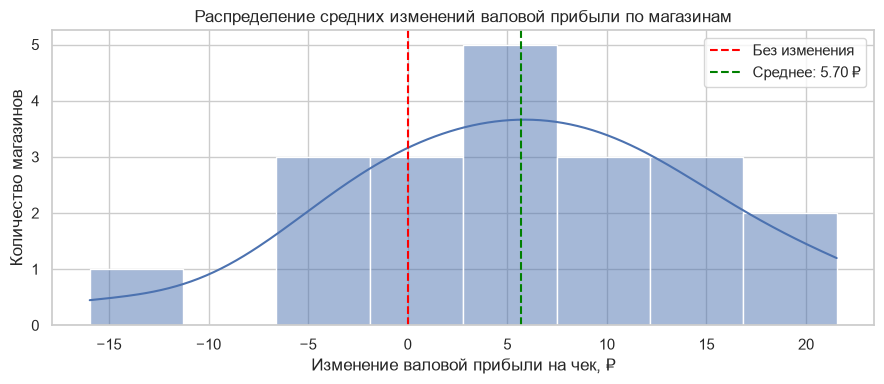

Шапиро — Уилк, W: 0.9782
p-value: 0.9087


In [61]:
fig, ax = plt.subplots(figsize=(9, 4))

sns.histplot(
    store_diff,
    bins=8,
    kde=True,
    ax=ax
)

ax.axvline(0, color="red", linestyle="--", label="Без изменения")
ax.axvline(
    store_diff.mean(),
    color="green",
    linestyle="--",
    label=f"Среднее: {store_diff.mean():.2f} ₽"
)

ax.set(
    title="Распределение средних изменений валовой прибыли по магазинам",
    xlabel="Изменение валовой прибыли на чек, ₽",
    ylabel="Количество магазинов"
)

ax.legend()
plt.tight_layout()
plt.show()

shapiro_result = stats.shapiro(store_diff)

print(f"Шапиро — Уилк, W: {shapiro_result.statistic:.4f}")
print(f"p-value: {shapiro_result.pvalue:.4f}")

In [62]:
# Двусторонняя проверка среднего изменения
h6_test = stats.ttest_1samp(
    store_diff,
    popmean=0,
    alternative="two-sided"
)

# Стандартная ошибка среднего
se_diff = stats.sem(store_diff)

# Степени свободы
df_h6 = len(store_diff) - 1

# 95%-ный доверительный интервал
ci_low, ci_high = stats.t.interval(
    confidence=0.95,
    df=df_h6,
    loc=store_diff.mean(),
    scale=se_diff
)

print(f"Среднее изменение: {store_diff.mean():.2f} ₽")
print(f"t-статистика: {h6_test.statistic:.4f}")
print(f"Степени свободы: {df_h6}")
print(f"p-value: {h6_test.pvalue:.6f}")
print(f"95% ДИ: [{ci_low:.2f}; {ci_high:.2f}] ₽")

Среднее изменение: 5.70 ₽
t-статистика: 2.7746
Степени свободы: 19
p-value: 0.012072
95% ДИ: [1.40; 9.99] ₽


In [63]:
cohens_dz = store_diff.mean() / store_diff.std(ddof=1)

print(f"Cohen's dz: {cohens_dz:.3f}")

Cohen's dz: 0.620


#### Итог проверки гипотезы H6

Для оценки изменения средней валовой прибыли на чек между 2024 и 2025 годами использованы сопоставимые пары «магазин × календарный месяц».

После агрегирования 240 месячных разностей до уровня 20 магазинов проведена двусторонняя проверка среднего изменения с помощью одновыборочного t-критерия.

Тест Шапиро — Уилка не выявил статистически значимого отклонения распределения магазинных разностей от нормального (W = 0,9782; p = 0,9087).

Результаты основной проверки:

- Среднее изменение: +5,70 ₽ на чек.
- t(19) = 2,7746.
- p-value = 0,0121.
- 95% доверительный интервал: [+1,40; +9,99] ₽.
- Cohen's dz = 0,620.
- Положительное изменение выявлено в 15 из 20 магазинов.

При уровне значимости 0,05 нулевая гипотеза об отсутствии среднего изменения отвергается.

**Статистический вывод:** обнаружено положительное среднее изменение оценочной валовой прибыли на чек между сопоставимыми периодами двух лет.

**Бизнес-интерпретация:** в большинстве магазинов наблюдается положительная динамика расчётного финансового показателя. Однако величина среднего изменения невелика в абсолютном выражении и требует оценки с учётом масштабов продаж.

**Ограничения:** используются справочные закупочные цены без исторической детализации, магазины получают одинаковый вес независимо от числа чеков, а общие временные факторы не учитываются. Результат не доказывает причинного влияния скидочной политики.

### 5. Бизнес-интерпретация результатов

#### 5.1. Ключевые результаты исследования

Проведённый статистический анализ выявил пять основных закономерностей.

**1. Высокий средний чек скидочных покупок не является достаточным подтверждением эффективности скидок.**

В исходном сравнении скидочные чеки идентифицированных покупателей превышают нескиточные на 24–93% в зависимости от формата магазина. Однако скидочные покупки также содержат больше товаров, а вероятность наличия скидочной позиции увеличивается с размером корзины.

**2. После учёта размера корзины наблюдаемая связь скидок с финансовыми показателями становится отрицательной.**

Регрессионный анализ на 11 036 чеках выявил отрицательную скорректированную разницу суммы чека (от −28,70 до −97,27 ₽) и оценочной валовой прибыли (от −30,65 до −58,87 ₽) во всех форматах.

Полученные результаты являются статистическими ассоциациями и не доказывают причинного влияния скидок.

**3. Формат магазина существенно связан с распределением валовой прибыли на чек.**

Средняя оценочная валовая прибыль составляет 127,88 ₽ в магазинах у дома, 253,88 ₽ в супермаркетах и 438,80 ₽ в гипермаркетах. Критерий Краскела — Уоллиса выявил статистически значимые различия между форматами (p < 0,001; ε² = 0,2757).

**4. Существенной связи частоты применения скидок с товарной категорией не обнаружено.**

Критерий χ² Пирсона не выявил статистически значимой зависимости категории товара и наличия скидки (p = 0,6318; V Крамера = 0,0155). Наблюдаемые доли скидочных позиций между категориями близки.

**5. Между 2024 и 2025 годами выявлено небольшое положительное изменение оценочной валовой прибыли на чек.**

Среднее изменение по 20 магазинам при сопоставлении одинаковых календарных месяцев составило +5,70 ₽ (p = 0,0121; 95% ДИ [+1,40; +9,99] ₽).

**Общий вывод:** эффективность скидочной политики нельзя оценивать исключительно по росту среднего чека и частоте применения скидок. Для управленческого решения необходим анализ валовой прибыли, состава покупательской корзины и различий между форматами магазинов.

#### 5.2. Управленческие рекомендации

По результатам статистического исследования сформированы пять рекомендаций для оценки и развития скидочной политики розничной сети.

**1. Пересмотреть подход к оценке эффективности скидок.**

Использовать средний чек только совместно с валовой прибылью, маржой, размером корзины и эффективным процентом скидки. Результаты H1–H3 показали, что более высокий средний чек скидочных покупок не является доказательством их большей экономической эффективности.

**2. Провести приоритетную проверку скидочной экономики магазинов у дома.**

В данном формате скидочные чеки характеризуются более высокой выручкой, но сравнительно небольшим приростом абсолютной валовой прибыли и наиболее выраженным снижением относительной маржи.

Необходимо дополнительно исследовать влияние глубины скидки, исходной маржинальности товаров и ассортиментного состава на финансовый результат покупок. Результаты не являются основанием для немедленного сокращения скидок.

**3. Разделять финансовые ориентиры по форматам магазинов.**

Выявленные статистические различия распределений валовой прибыли на чек обосновывают необходимость внутриформатных сравнений. Единые абсолютные ориентиры среднего чека и валовой прибыли для всех магазинов могут приводить к некорректной оценке результатов.

**4. Не использовать частоту скидок как единственный критерий изменения категорийной политики.**

Существенной статистической связи между категорией товара и частотой скидок не обнаружено. Для принятия категорийных решений требуется дополнительный анализ глубины скидок, закупочной стоимости и валовой маржи.

**5. Проверить причинный эффект скидок экспериментально.**

Наблюдательное исследование не позволяет определить, как изменились бы покупки при отсутствии скидок.

Для принятия решений об изменении скидочной политики рекомендуется контролируемый эксперимент с заранее определёнными метриками, включая валовую прибыль на рандомизированного покупателя за фиксированный период.

**Приоритет реализации:** в первую очередь — совершенствование текущей отчётности и детальный анализ скидочной экономики магазинов у дома. Изменение правил предоставления скидок требует дополнительной проверки причинного эффекта.

#### 5.3. Ограничения исследования

При интерпретации результатов необходимо учитывать следующие ограничения.

**1. Наблюдательный характер данных.** Исследование выявляет статистические ассоциации между скидками, размером корзины и финансовыми показателями, но не позволяет установить причинный эффект предоставления скидок. Отсутствуют данные о поведении покупателей в альтернативном сценарии без скидок.

**2. Использование справочных закупочных цен.** Себестоимость рассчитана на основе закупочных цен из справочника товаров без учёта их исторических изменений. Поэтому показатели валовой прибыли и маржинальности являются оценочными. Это ограничивает интерпретацию финансовых результатов и динамики между 2024 и 2025 годами.

**3. Неполный контроль факторов в регрессионном анализе.** Модели H2 и H3 учитывают формат магазина и количество товарных позиций, но не контролируют полностью ассортиментный состав, количество единиц внутри позиции, особенности клиентов и торговых точек. Результаты ограничены областью сопоставимости, включающей 11 036 чеков.

**4. Возможная зависимость наблюдений.** Товарные позиции внутри чеков, повторные покупки клиентов и чеки отдельных магазинов могут быть статистически зависимы. Это особенно важно для интерпретации результатов H1, H4 и H5, где не вся структура зависимости учтена статистическими критериями.

**5. Синтетическое происхождение данных.** Выявленные закономерности могут отражать правила генерации датасета и не должны автоматически переноситься на реальные торговые сети.

#### Направления дальнейшего анализа

Для принятия решений об изменении скидочной политики необходимо:

1. Получить исторические закупочные цены и фактическую себестоимость продаж.
2. Дополнить информацию об условиях скидочных акций и истории покупок.
3. Исследовать прибыльность скидочных корзин с более подробным учётом ассортимента.
4. Проверить устойчивость статистических выводов методами, учитывающими зависимость наблюдений.
5. Провести контролируемый эксперимент для оценки причинного влияния скидок на выручку и валовую прибыль на покупателя.

**Заключение:** результаты исследования пригодны для выявления направлений дальнейшего анализа и совершенствования управленческой отчётности. Они не являются самостоятельным основанием для изменения размера скидок или сокращения программы лояльности.

### 6. Визуализация ключевых результатов

Для представления результатов исследования в GitHub подготовлены три итоговые визуализации:

1. Сравнение среднего чека скидочных и нескиточных покупок.
2. Сравнение исходных и скорректированных различий среднего чека.
3. Сравнение средней валовой прибыли на чек между форматами магазинов.

Графики предназначены для краткого представления результатов исследования и сопровождаются пояснениями об ограничениях интерпретации.

In [64]:
# Notebook запускается из папки notebooks
FIGURES_DIR = Path("../reports/figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")

format_order = ["у дома", "супермаркет", "гипермаркет"]

print("Папка для графиков:", FIGURES_DIR.resolve())

Папка для графиков: D:\Projects\simulative-retail-discount-statistical-analysis\reports\figures


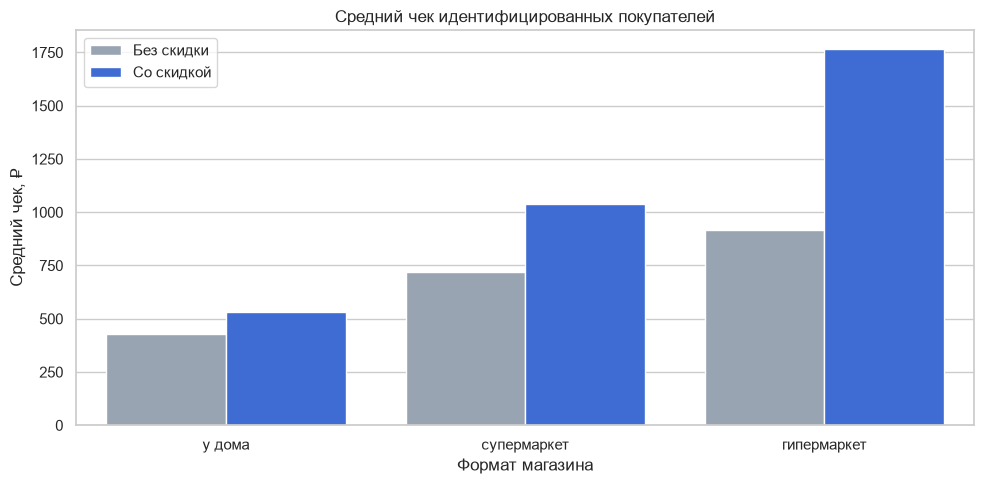

In [65]:
# График № 1. Средний чек со скидкой и без скидки
plot_data = (
    identified_checks
    .groupby(["store_format", "has_discount"], as_index=False)
    .agg(mean_revenue=("revenue", "mean"))
)

plot_data["Тип покупки"] = plot_data["has_discount"].map({
    False: "Без скидки",
    True: "Со скидкой"
})

fig, ax = plt.subplots(figsize=(10, 5))

sns.barplot(
    data=plot_data,
    x="store_format",
    y="mean_revenue",
    hue="Тип покупки",
    order=format_order,
    hue_order=["Без скидки", "Со скидкой"],
    palette=["#94A3B8", "#2563EB"],
    errorbar=None,
    ax=ax
)

ax.set(
    title="Средний чек идентифицированных покупателей",
    xlabel="Формат магазина",
    ylabel="Средний чек, ₽"
)

ax.legend(title="")
ax.set_ylim(bottom=0)

plt.tight_layout()

fig.savefig(
    FIGURES_DIR / "average_check_by_discount.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

Скидочные чеки имеют более высокую среднюю сумму во всех форматах, но также содержат больше товаров. Сравнение не учитывает размер корзины.

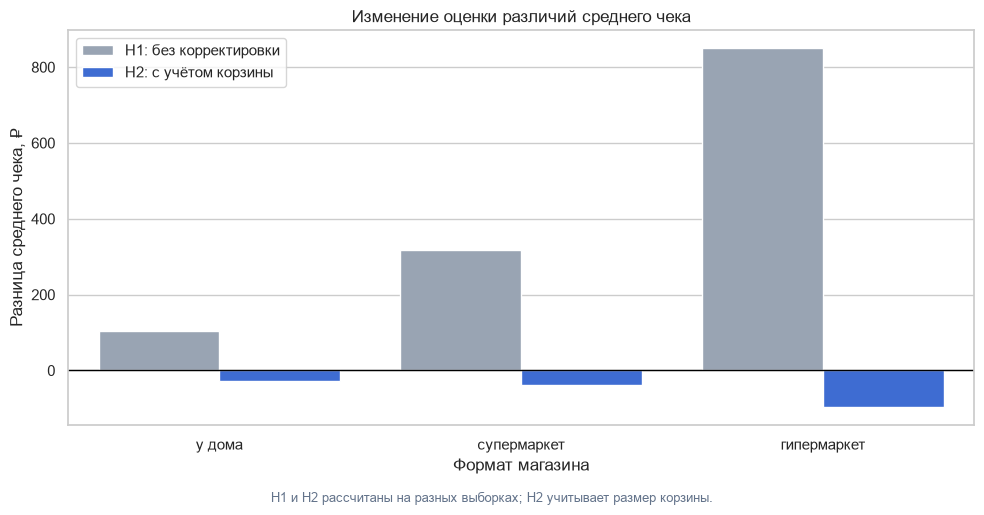

In [66]:
# График № 2. Сравнение H1 и H2
h1_plot = (
    h1_results[["Формат", "Разница средних, ₽"]]
    .rename(columns={
        "Формат": "store_format",
        "Разница средних, ₽": "difference"
    })
    .assign(comparison="H1: без корректировки")
)

h2_plot = (
    h2_results[["coefficient"]]
    .reset_index()
    .rename(columns={"coefficient": "difference"})
)

h2_plot["store_format"] = (
    h2_plot.iloc[:, 0]
    .str.extract(r"\[([^\]]+)\]")[0]
)

h2_plot["comparison"] = "H2: с учётом корзины"

plot_comparison = pd.concat(
    [
        h1_plot[["store_format", "difference", "comparison"]],
        h2_plot[["store_format", "difference", "comparison"]]
    ],
    ignore_index=True
)

fig, ax = plt.subplots(figsize=(10, 5))

sns.barplot(
    data=plot_comparison,
    x="store_format",
    y="difference",
    hue="comparison",
    order=format_order,
    hue_order=[
        "H1: без корректировки",
        "H2: с учётом корзины"
    ],
    palette=["#94A3B8", "#2563EB"],
    errorbar=None,
    ax=ax
)

ax.axhline(0, color="black", linewidth=1)

ax.set(
    title="Изменение оценки различий среднего чека",
    xlabel="Формат магазина",
    ylabel="Разница среднего чека, ₽"
)

ax.legend(title="")

fig.text(
    0.5, -0.02,
    "H1 и H2 рассчитаны на разных выборках; H2 учитывает размер корзины.",
    ha="center",
    fontsize=9,
    color="#64748B"
)

plt.tight_layout()

fig.savefig(
    FIGURES_DIR / "average_check_adjustment.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

Первоначально положительные различия среднего чека сменяются отрицательными после ограничения выборки и учёта количества товарных позиций. Изменение нельзя интерпретировать исключительно как эффект статистической корректировки или как причинное влияние скидок.

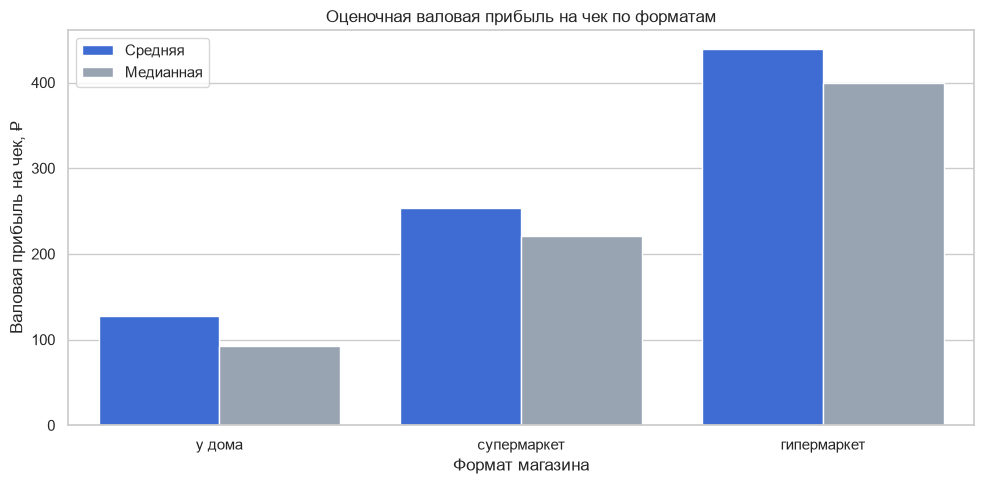

In [67]:
# График № 3. Валовая прибыль по форматам
profit_plot = (
    sales_checks
    .groupby("store_format", as_index=False)
    .agg(
        mean_profit=("gross_profit", "mean"),
        median_profit=("gross_profit", "median")
    )
)

profit_long = profit_plot.melt(
    id_vars="store_format",
    value_vars=["mean_profit", "median_profit"],
    var_name="metric",
    value_name="gross_profit"
)

profit_long["metric"] = profit_long["metric"].map({
    "mean_profit": "Средняя",
    "median_profit": "Медианная"
})

fig, ax = plt.subplots(figsize=(10, 5))

sns.barplot(
    data=profit_long,
    x="store_format",
    y="gross_profit",
    hue="metric",
    order=format_order,
    hue_order=["Средняя", "Медианная"],
    palette=["#2563EB", "#94A3B8"],
    errorbar=None,
    ax=ax
)

ax.set(
    title="Оценочная валовая прибыль на чек по форматам",
    xlabel="Формат магазина",
    ylabel="Валовая прибыль на чек, ₽"
)

ax.legend(title="")
ax.set_ylim(bottom=0)

plt.tight_layout()

fig.savefig(
    FIGURES_DIR / "gross_profit_by_format.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

Распределения валовой прибыли на чек существенно различаются между форматами. Это не означает, что один формат экономически эффективнее другого после учёта операционных расходов.